# IVF Treatment Outcome Analysis & Success Rate Optimization Using Python

**Synthetic educational analytics project — not clinical evidence.**

## 1. Project Introduction

A reproducible synthetic-data analysis of IVF cycle patterns, outcomes and costs.

## 2. Business Problem

A fictional clinic seeks operational indicators, outcome denominators, and cost patterns. No clinical decisions are supported.

## 3. Objectives

Explore demographics, treatment and embryo features; quantify outcomes; test associations; communicate bounded operational insights.

## 4. Dataset Source and Synthetic Data Disclaimer

All records are generated with NumPy seed 42. No real patient data or external patient records are used.

## 5. Library Imports

Use pandas, numpy, scipy, matplotlib, seaborn, pathlib, JSON, and project scripts.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / "data").exists(): ROOT = ROOT.parent
print("Project root:", ROOT)

Project root: /home/user/IVF-Treatment-Outcome-Analysis


## 6. Dataset Generation

Run the deterministic synthetic generator from the repository root when regeneration is required.

In [2]:
# Optional deterministic regeneration. Existing CSVs are used for the remaining analysis.
# %run src/generate_synthetic_data.py
print("Generator: src/generate_synthetic_data.py (fixed seed = 42)")

Generator: src/generate_synthetic_data.py (fixed seed = 42)


## 7. Data Loading

Load the five cleaned tables and analytical results; raw sources remain available in data/raw.

In [3]:
raw_dir=ROOT/"data/raw"; clean_dir=ROOT/"data/cleaned"
patients=pd.read_csv(clean_dir/"cleaned_patients.csv")
cycles=pd.read_csv(clean_dir/"cleaned_treatment_cycles.csv", parse_dates=["Treatment_Date"])
embryos=pd.read_csv(clean_dir/"cleaned_embryo_grading.csv")
outcomes=pd.read_csv(clean_dir/"cleaned_implantation_outcomes.csv")
costs=pd.read_csv(clean_dir/"cleaned_treatment_costs.csv")
results=json.load(open(ROOT/"docs/analytical_results.json"))
print({"patients":patients.shape,"cycles":cycles.shape,"embryos":embryos.shape,"outcomes":outcomes.shape,"costs":costs.shape})

{'patients': (3897, 12), 'cycles': (5277, 18), 'embryos': (16928, 11), 'outcomes': (5277, 7), 'costs': (5277, 12)}


## 8. Data Understanding

Inspect shape, columns, dtypes, samples and categorical levels.

In [4]:
display(cycles.head(10)); display(cycles.tail(10)); display(patients.describe(include="all").T.head(12))
print("Cycle dtypes:"); display(cycles.dtypes)

,Cycle_ID,Patient_ID,Treatment_Date,Treatment_Type,Stimulation_Protocol,Retrieved_Oocytes,Mature_Oocytes,Fertilized_Oocytes,Fertilization_Method,Number_of_Embryos,Number_of_Embryos_Transferred,Transfer_Type,Treatment_Year,Treatment_Quarter,Oocyte_Maturation_Rate,Fertilization_Rate,Embryo_Development_Rate,Transfer_Strategy
0,CYC-200001,PT-13731,2023-01-01,IVF + PGT-A,GnRH Antagonist,8,8,7,ICSI,3,2,Frozen-Thawed Transfer,2023,2023Q1,1.0000,0.8750,0.4286,DET (2 Embryos)
1,CYC-200002,PT-10166,2023-01-01,ICSI,GnRH Agonist Long,6,4,2,ICSI,0,0,No Transfer,2023,2023Q1,0.6667,0.5000,0.0000,No Transfer (0)
2,CYC-200003,PT-12040,2023-01-01,IVF + PGT-A,GnRH Antagonist,11,8,7,ICSI,2,1,Frozen-Thawed Transfer,2023,2023Q1,0.7273,0.8750,0.2857,eSET (1 Embryo)
3,CYC-200004,PT-10563,2023-01-01,Mild Stimulation IVF,Mild / Minimal Stimulation,7,3,3,ICSI,1,1,Fresh Transfer,2023,2023Q1,0.4286,1.0000,0.3333,eSET (1 Embryo)
4,CYC-200005,PT-11973,2023-01-01,Mild Stimulation IVF,Mild / Minimal Stimulation,6,5,3,Conventional Insemination,2,1,Fresh Transfer,2023,2023Q1,0.8333,0.6000,0.6667,eSET (1 Embryo)
5,CYC-200006,PT-13152,2023-01-01,IVF + PGT-A,GnRH Agonist Long,14,14,14,ICSI,8,1,Frozen-Thawed Transfer,2023,2023Q1,1.0000,1.0000,0.5714,eSET (1 Embryo)
6,CYC-200007,PT-13287,2023-01-01,Conventional IVF,GnRH Antagonist,7,6,5,Conventional Insemination,3,2,Fresh Transfer,2023,2023Q1,0.8571,0.8333,0.6000,DET (2 Embryos)
7,CYC-200008,PT-13463,2023-01-01,Conventional IVF,GnRH Agonist Long,8,7,6,Conventional Insemination,5,1,Frozen-Thawed Transfer,2023,2023Q1,0.8750,0.8571,0.8333,eSET (1 Embryo)
8,CYC-200009,PT-12696,2023-01-02,Conventional IVF,Flare-Up Protocol,6,6,3,Split IVF-ICSI,0,0,No Transfer,2023,2023Q1,1.0000,0.5000,0.0000,No Transfer (0)
9,CYC-200010,PT-11805,2023-01-02,Mild Stimulation IVF,Mild / Minimal Stimulation,16,14,8,Conventional Insemination,7,1,Fresh Transfer,2023,2023Q1,0.8750,0.5714,0.8750,eSET (1 Embryo)


,Cycle_ID,Patient_ID,Treatment_Date,Treatment_Type,Stimulation_Protocol,Retrieved_Oocytes,Mature_Oocytes,Fertilized_Oocytes,Fertilization_Method,Number_of_Embryos,Number_of_Embryos_Transferred,Transfer_Type,Treatment_Year,Treatment_Quarter,Oocyte_Maturation_Rate,Fertilization_Rate,Embryo_Development_Rate,Transfer_Strategy
5267,CYC-205311,PT-13250,2025-12-28,Conventional IVF,GnRH Antagonist,7,5,5,Conventional Insemination,3,2,Fresh Transfer,2025,2025Q4,0.7143,1.0000,0.6000,DET (2 Embryos)
5268,CYC-205312,PT-13151,2025-12-28,IVF + PGT-A,GnRH Agonist Long,9,6,4,ICSI,3,1,Frozen-Thawed Transfer,2025,2025Q4,0.6667,0.6667,0.7500,eSET (1 Embryo)
5269,CYC-205313,PT-12766,2025-12-29,ICSI,GnRH Agonist Long,7,4,4,ICSI,3,1,Frozen-Thawed Transfer,2025,2025Q4,0.5714,1.0000,0.7500,eSET (1 Embryo)
5270,CYC-205314,PT-13383,2025-12-29,Conventional IVF,GnRH Antagonist,10,8,6,Conventional Insemination,3,2,Frozen-Thawed Transfer,2025,2025Q4,0.8000,0.7500,0.5000,DET (2 Embryos)
5271,CYC-205315,PT-11858,2025-12-29,ICSI,GnRH Antagonist,9,6,6,ICSI,3,1,Frozen-Thawed Transfer,2025,2025Q4,0.6667,1.0000,0.5000,eSET (1 Embryo)
5272,CYC-205316,PT-12026,2025-12-30,Mild Stimulation IVF,Mild / Minimal Stimulation,8,7,6,Conventional Insemination,4,1,Fresh Transfer,2025,2025Q4,0.8750,0.8571,0.6667,eSET (1 Embryo)
5273,CYC-205317,PT-13623,2025-12-30,ICSI,GnRH Antagonist,8,4,4,ICSI,2,1,Fresh Transfer,2025,2025Q4,0.5000,1.0000,0.5000,eSET (1 Embryo)
5274,CYC-205318,PT-12774,2025-12-30,IVF + PGT-A,GnRH Antagonist,6,5,4,ICSI,2,2,Frozen-Thawed Transfer,2025,2025Q4,0.8333,0.8000,0.5000,DET (2 Embryos)
5275,CYC-205319,PT-10968,2025-12-30,ICSI,GnRH Antagonist,17,13,11,ICSI,6,1,Fresh Transfer,2025,2025Q4,0.7647,0.8462,0.5455,eSET (1 Embryo)
5276,CYC-205320,PT-12806,2025-12-30,ICSI,GnRH Agonist Long,8,7,6,ICSI,6,1,Frozen-Thawed Transfer,2025,2025Q4,0.8750,0.8571,1.0000,eSET (1 Embryo)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Patient_ID,3897,3897,PT-10001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,3897.0,NaN,NaN,NaN,33.918655,4.555195,22.0,31.0,34.0,37.0,45.0
BMI,3897.0,NaN,NaN,NaN,25.061842,4.319715,17.4,22.1,24.6,27.6,42.5
Infertility_Duration_Years,3897.0,NaN,NaN,NaN,3.465615,2.065294,0.5,1.9,3.1,4.6,14.5
Infertility_Type,3897,2,Primary,2597,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Previous_IVF_Attempts,3897.0,NaN,NaN,NaN,0.774442,0.918207,0.0,0.0,1.0,1.0,5.0
AMH_Level,3897.0,NaN,NaN,NaN,3.487259,2.174543,0.29,1.95,2.98,4.45,11.5
FSH_Level,3897.0,NaN,NaN,NaN,8.203182,2.121067,2.8,6.77,8.23,9.63,16.01
Medical_History_Category,3897,7,Male Factor,983,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age_Group,3897,5,30-34,1461,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Cycle dtypes:


Cycle_ID                                 object
Patient_ID                               object
Treatment_Date                   datetime64[ns]
Treatment_Type                           object
Stimulation_Protocol                     object
Retrieved_Oocytes                         int64
Mature_Oocytes                            int64
Fertilized_Oocytes                        int64
Fertilization_Method                     object
Number_of_Embryos                         int64
Number_of_Embryos_Transferred             int64
Transfer_Type                            object
Treatment_Year                            int64
Treatment_Quarter                        object
Oocyte_Maturation_Rate                  float64
Fertilization_Rate                      float64
Embryo_Development_Rate                 float64
Transfer_Strategy                        object
dtype: object

## 9. Data Profiling

Review the stored profiling summary and before/after data quality report.

In [5]:
quality=json.load(open(ROOT/"docs/data_quality_summary.json")); print(json.dumps(quality,indent=2)[:10000])

{
  "datasets": [
    {
      "raw_file": "patients.csv",
      "clean_file": "cleaned_patients.csv",
      "raw_rows": 3925,
      "raw_cols": 9,
      "missing_before": 281,
      "duplicates_removed": 25,
      "invalid_removed": 3,
      "invalid_corrected_or_imputed": 7,
      "final_rows": 3897,
      "final_cols": 12,
      "missing_after": 0,
      "notes": "Removed 25 exact duplicate Patient_ID rows and 3 records with impossible maternal ages (-29, 14, 71). Converted 7 impossible BMI/AMH/FSH entries to NaN and applied diagnosis/age-stratified median imputation. Standardized casing/whitespace in Infertility_Type and Medical_History_Category."
    },
    {
      "raw_file": "ivf_treatment_cycles.csv",
      "clean_file": "cleaned_treatment_cycles.csv",
      "raw_rows": 5365,
      "raw_cols": 12,
      "missing_before": 34,
      "duplicates_removed": 45,
      "invalid_removed": 43,
      "invalid_corrected_or_imputed": 194,
      "final_rows": 5277,
      "final_cols": 18,
  

## 10. Data Cleaning

Cleaning decisions are implemented in src/clean_and_preprocess.py and documented in docs/DATA_QUALITY_REPORT.md.

In [6]:
display(pd.read_csv(ROOT/"docs/iqr_outlier_summary.csv").head(20))
print((ROOT/"docs/DATA_QUALITY_REPORT.md").read_text()[:5000])

,Dataset,Variable,Count,Mean,SD,Median,Q1,Q3,IQR,Lower_Fence,Upper_Fence,Outliers_Below,Outliers_Above,Total_IQR_Outliers,Outlier_Pct
0,cleaned_patients.csv,Age,3897,33.919,4.555,34.00,31.00,37.00,6.00,22.000,46.000,0,0,0,0.00
1,cleaned_patients.csv,BMI,3897,25.062,4.320,24.60,22.10,27.60,5.50,13.850,35.850,0,56,56,1.44
2,cleaned_patients.csv,Infertility_Duration_Years,3897,3.466,2.065,3.10,1.90,4.60,2.70,-2.150,8.650,0,102,102,2.62
3,cleaned_patients.csv,Previous_IVF_Attempts,3897,0.774,0.918,1.00,0.00,1.00,1.00,-1.500,2.500,0,191,191,4.90
4,cleaned_patients.csv,AMH_Level,3897,3.487,2.175,2.98,1.95,4.45,2.50,-1.800,8.200,0,168,168,4.31
5,cleaned_patients.csv,FSH_Level,3897,8.203,2.121,8.23,6.77,9.63,2.86,2.480,13.920,0,10,10,0.26
6,cleaned_treatment_cycles.csv,Retrieved_Oocytes,5277,8.936,4.259,8.00,6.00,12.00,6.00,-3.000,21.000,0,42,42,0.80
7,cleaned_treatment_cycles.csv,Mature_Oocytes,5277,6.991,3.636,7.00,4.00,9.00,5.00,-3.500,16.500,0,74,74,1.40
8,cleaned_treatment_cycles.csv,Fertilized_Oocytes,5277,5.174,2.998,5.00,3.00,7.00,4.00,-3.000,13.000,0,67,67,1.27
9,cleaned_treatment_cycles.csv,Number_of_Embryos,5277,3.208,2.254,3.00,2.00,4.00,2.00,-1.000,7.000,0,241,241,4.57


# Data Quality Assessment & Preprocessing Report

> **Synthetic Data Disclaimer:** All datasets evaluated in this report are 100% synthetic and generated programmatically for healthcare analytics evaluation. No real patient data is included.

## 1. Executive Summary of Cleaning Audit

| Raw Dataset | Original Rows | Missing Cells (Raw) | Duplicates Removed | Invalid / Orphan Removed | Imputed / Reconciled | Final Clean Rows | Residual Missing |
|---|---:|---:|---:|---:|---:|---:|---:|
| `patients.csv` | 3,925 | 281 | 25 | 3 | 7 | **3,897** | 0 |
| `ivf_treatment_cycles.csv` | 5,365 | 34 | 45 | 43 | 194 | **5,277** | 0 |
| `embryo_grading.csv` | 17,072 | 266 | 35 | 109 | 262 | **16,928** | 0 |
| `implantation_outcomes.csv` | 5,340 | 42 | 20 | 43 | 42 | **5,277** | 0 |
| `treatment_costs.csv` | 5,338 | 156 | 18 | 43 | 332 | **5,277** | 0 |

## 2. Detailed Cleaning Decisions & Justifications

### `patients.csv` -> `cleaned_patients.csv`
- **Audit Summary:** Removed 25 exact duplicate Pati

## 11. Data Validation

Check keys, referential integrity, missing values, biological funnel constraints and exact cost totals.

In [7]:
assert not patients.Patient_ID.duplicated().any()
assert not cycles.Cycle_ID.duplicated().any()
assert not outcomes.Cycle_ID.duplicated().any()
assert not costs.Cycle_ID.duplicated().any()
assert cycles.Patient_ID.isin(patients.Patient_ID).all()
assert outcomes.Cycle_ID.isin(cycles.Cycle_ID).all() and costs.Cycle_ID.isin(cycles.Cycle_ID).all()
assert cycles.Mature_Oocytes.le(cycles.Retrieved_Oocytes).all()
assert cycles.Number_of_Embryos_Transferred.le(cycles.Number_of_Embryos).all()
assert (costs.Total_Treatment_Cost.round(2)==costs[["Consultation_Cost","Medication_Cost","Laboratory_Cost","Procedure_Cost","Additional_Cost"]].sum(axis=1).round(2)).all()
print("Validation passed; cleaned tables missing values:", int(sum(x.isna().sum().sum() for x in [patients,cycles,embryos,outcomes,costs])))

Validation passed; cleaned tables missing values: 0


## 12. Feature Engineering

Cleaned cycle data includes derived outcome/rate and patient grouping features; analytical tables join patient, cycle, outcome and cost records.

In [8]:
print("Derived fields:", [c for c in cycles.columns if c not in pd.read_csv(clean_dir/"cleaned_treatment_cycles.csv").columns[:12]])
display(cycles.head())

Derived fields: ['Treatment_Year', 'Treatment_Quarter', 'Oocyte_Maturation_Rate', 'Fertilization_Rate', 'Embryo_Development_Rate', 'Transfer_Strategy']


,Cycle_ID,Patient_ID,Treatment_Date,Treatment_Type,Stimulation_Protocol,Retrieved_Oocytes,Mature_Oocytes,Fertilized_Oocytes,Fertilization_Method,Number_of_Embryos,Number_of_Embryos_Transferred,Transfer_Type,Treatment_Year,Treatment_Quarter,Oocyte_Maturation_Rate,Fertilization_Rate,Embryo_Development_Rate,Transfer_Strategy
0,CYC-200001,PT-13731,2023-01-01,IVF + PGT-A,GnRH Antagonist,8,8,7,ICSI,3,2,Frozen-Thawed Transfer,2023,2023Q1,1.0000,0.875,0.4286,DET (2 Embryos)
1,CYC-200002,PT-10166,2023-01-01,ICSI,GnRH Agonist Long,6,4,2,ICSI,0,0,No Transfer,2023,2023Q1,0.6667,0.500,0.0000,No Transfer (0)
2,CYC-200003,PT-12040,2023-01-01,IVF + PGT-A,GnRH Antagonist,11,8,7,ICSI,2,1,Frozen-Thawed Transfer,2023,2023Q1,0.7273,0.875,0.2857,eSET (1 Embryo)
3,CYC-200004,PT-10563,2023-01-01,Mild Stimulation IVF,Mild / Minimal Stimulation,7,3,3,ICSI,1,1,Fresh Transfer,2023,2023Q1,0.4286,1.000,0.3333,eSET (1 Embryo)
4,CYC-200005,PT-11973,2023-01-01,Mild Stimulation IVF,Mild / Minimal Stimulation,6,5,3,Conventional Insemination,2,1,Fresh Transfer,2023,2023Q1,0.8333,0.600,0.6667,eSET (1 Embryo)


## 13. Exploratory Data Analysis

Summarize patient characteristics, cycle modalities, embryo quality, outcomes and itemized treatment costs.

In [9]:
print("Outcome rates (counts and explicit denominators):")
print(json.dumps(results["outcome_rates"],indent=2))
print("\nCost summary:")
print(json.dumps(results["cost_summary"],indent=2))

Outcome rates (counts and explicit denominators):
{
  "counts": {
    "Initiated_Cycles": 5277,
    "Embryo_Transfer_Cycles": 4672,
    "No_Transfer_Cycles": 605,
    "Positive_hCG": 2553,
    "Implanted_Cycles": 2217,
    "Clinical_Pregnancies": 2021,
    "Live_Births": 1711
  },
  "per_initiated_cycle_pct": {
    "Transfer_Completion_Rate": 88.54,
    "Positive_hCG_Rate": 48.38,
    "Cycle_Implantation_Proportion": 42.01,
    "Clinical_Pregnancy_Rate": 38.3,
    "Live_Birth_Rate": 32.42
  },
  "per_embryo_transfer_pct": {
    "Positive_hCG_Rate": 54.64,
    "Cycle_Implantation_Proportion": 47.45,
    "Clinical_Pregnancy_Rate": 43.26,
    "Live_Birth_Rate": 36.62
  },
  "stage_progression_conditional_pct": {
    "Implantation_given_Pos_hCG": 86.84,
    "Biochemical_Loss_given_Pos_hCG": 13.16,
    "Clinical_Preg_given_Implantation": 91.16,
    "Live_Birth_given_Clinical_Preg": 84.66
  },
  "completed_followup_sensitivity": {
    "Completed_ET_Cycles": 4607,
    "Live_Birth_Rate_Complet

## 14. Statistical Analysis

Pearson/Spearman correlations, chi-square tests with Cramer’s V, rank tests with epsilon-squared, and multivariable logistic regression are reported descriptively.

In [10]:
display(pd.DataFrame(results["hypothesis_tests"]))
display(pd.DataFrame(results["pairwise_correlations"]).head(20))
display(pd.DataFrame(results["logistic_regression_et_live_birth"]))

,Test_Name,Method,Sample_N,Statistic,df,p_value,Effect_Size_Metric,Effect_Size,Assumptions_Check,Significant_at_0_05
0,Best Transferred Embryo Quality vs Implantatio...,Pearson Chi-Square Test of Independence,4672,138.963,3,6.324218e-30,Cramer's V,0.1725,Independent cycle/transfer observations; minim...,True
1,Maternal Age Group vs Clinical Pregnancy (ET C...,Pearson Chi-Square Test of Independence,4672,76.120,4,1.154969e-15,Cramer's V,0.1276,Independent cycle/transfer observations; minim...,True
2,Maternal Age Group vs Live Birth (Initiated Cy...,Pearson Chi-Square Test of Independence,5277,128.957,4,6.508176e-27,Cramer's V,0.1563,Independent cycle/transfer observations; minim...,True
3,Embryo Day (Day 5 vs Day 3) vs Implantation (E...,Pearson Chi-Square Test of Independence,4672,48.429,1,3.425358e-12,Cramer's V,0.1023,Independent cycle/transfer observations; minim...,True
4,Treatment Type vs Live Birth (Crude / Unadjust...,Pearson Chi-Square Test of Independence,5277,11.294,3,1.023720e-02,Cramer's V,0.0463,Independent cycle/transfer observations; minim...,True
5,Transfer Type (FET vs Fresh) vs Live Birth (ET...,Pearson Chi-Square Test of Independence,4672,1.164,1,2.805598e-01,Cramer's V,0.0162,Independent cycle/transfer observations; minim...,False
6,Infertility Type (Primary vs Secondary) vs Liv...,Pearson Chi-Square Test of Independence,4672,4.262,1,3.896276e-02,Cramer's V,0.0307,Independent cycle/transfer observations; minim...,True
7,BMI Category vs Clinical Pregnancy (ET Cycles),Pearson Chi-Square Test of Independence,4672,3.712,3,2.943019e-01,Cramer's V,0.0282,Independent cycle/transfer observations; minim...,False
8,Total Treatment Cost across Treatment Types,Kruskal-Wallis H Test (with One-Way ANOVA check),5277,3040.754,3,0.000000e+00,Epsilon-squared (eps^2),0.5763,Right-skewed cost distributions & Levene varia...,True
9,Retrieved Oocytes across Stimulation Protocols,Kruskal-Wallis H Test,5277,497.016,3,2.114746e-107,Epsilon-squared (eps^2),0.0942,Count outcome with positive skewness; non-para...,True


,Var_1,Var_2,N,Pearson_r,Pearson_p,Spearman_rho,Spearman_p
0,Age,AMH_Level,5277,-0.4525,1.012117e-264,-0.4431,1.117001e-252
1,AMH_Level,FSH_Level,5277,-0.4169,5.259559e-221,-0.4228,6.825659e-228
2,AMH_Level,Retrieved_Oocytes,5277,0.3656,1.376856e-166,0.3692,4.647770e-170
3,Age,Retrieved_Oocytes,5277,-0.3075,5.941743e-116,-0.2996,6.581725e-110
4,Retrieved_Oocytes,Mature_Oocytes,5277,0.9193,0.000000e+00,0.9147,0.000000e+00
5,Mature_Oocytes,Number_of_Embryos,5277,0.7504,0.000000e+00,0.7329,0.000000e+00
6,Medication_Cost,Total_Treatment_Cost,5277,0.6155,0.000000e+00,0.5621,0.000000e+00
7,Laboratory_Cost,Total_Treatment_Cost,5277,0.7914,0.000000e+00,0.7663,0.000000e+00
8,Best_Quality_Score,Implanted_Bin,4672,0.1724,1.695486e-32,0.1670,1.456288e-30
9,Age,Live_Birth_Bin,4672,-0.1412,3.148596e-22,-0.1406,4.502321e-22


,Feature,Beta,SE,Odds_Ratio,OR_CI_Lower,OR_CI_Upper,Wald_Z,p_value
0,Intercept,-1.4792,0.1245,0.228,0.179,0.291,-11.886,0.000000e+00
1,Age_per_5yr,-0.2862,0.0370,0.751,0.699,0.808,-7.736,1.021405e-14
2,Embryo_Excellent_vs_FairPoor,0.7413,0.0996,2.099,1.727,2.551,7.444,9.747758e-14
3,Embryo_Good_vs_FairPoor,0.4860,0.1038,1.626,1.327,1.992,4.684,2.819862e-06
4,Day5_vs_Day3,0.3516,0.0812,1.421,1.212,1.667,4.328,1.503418e-05
5,PGT_A_vs_Conventional,0.2671,0.0961,1.306,1.082,1.577,2.781,5.421930e-03
6,ICSI_vs_Conventional,0.0999,0.0701,1.105,0.963,1.268,1.426,1.538515e-01
7,FET_vs_Fresh,0.0195,0.0664,1.020,0.895,1.161,0.293,7.696185e-01
8,Multi_Embryo_Transfer_vs_eSET,0.1552,0.0707,1.168,1.017,1.341,2.196,2.806782e-02
9,Obese_BMI_ge_30,-0.1383,0.0922,0.871,0.727,1.043,-1.499,1.338553e-01


## 15. Data Visualization

Display all PNG charts inline from the visualizations folder.

age_distribution.png


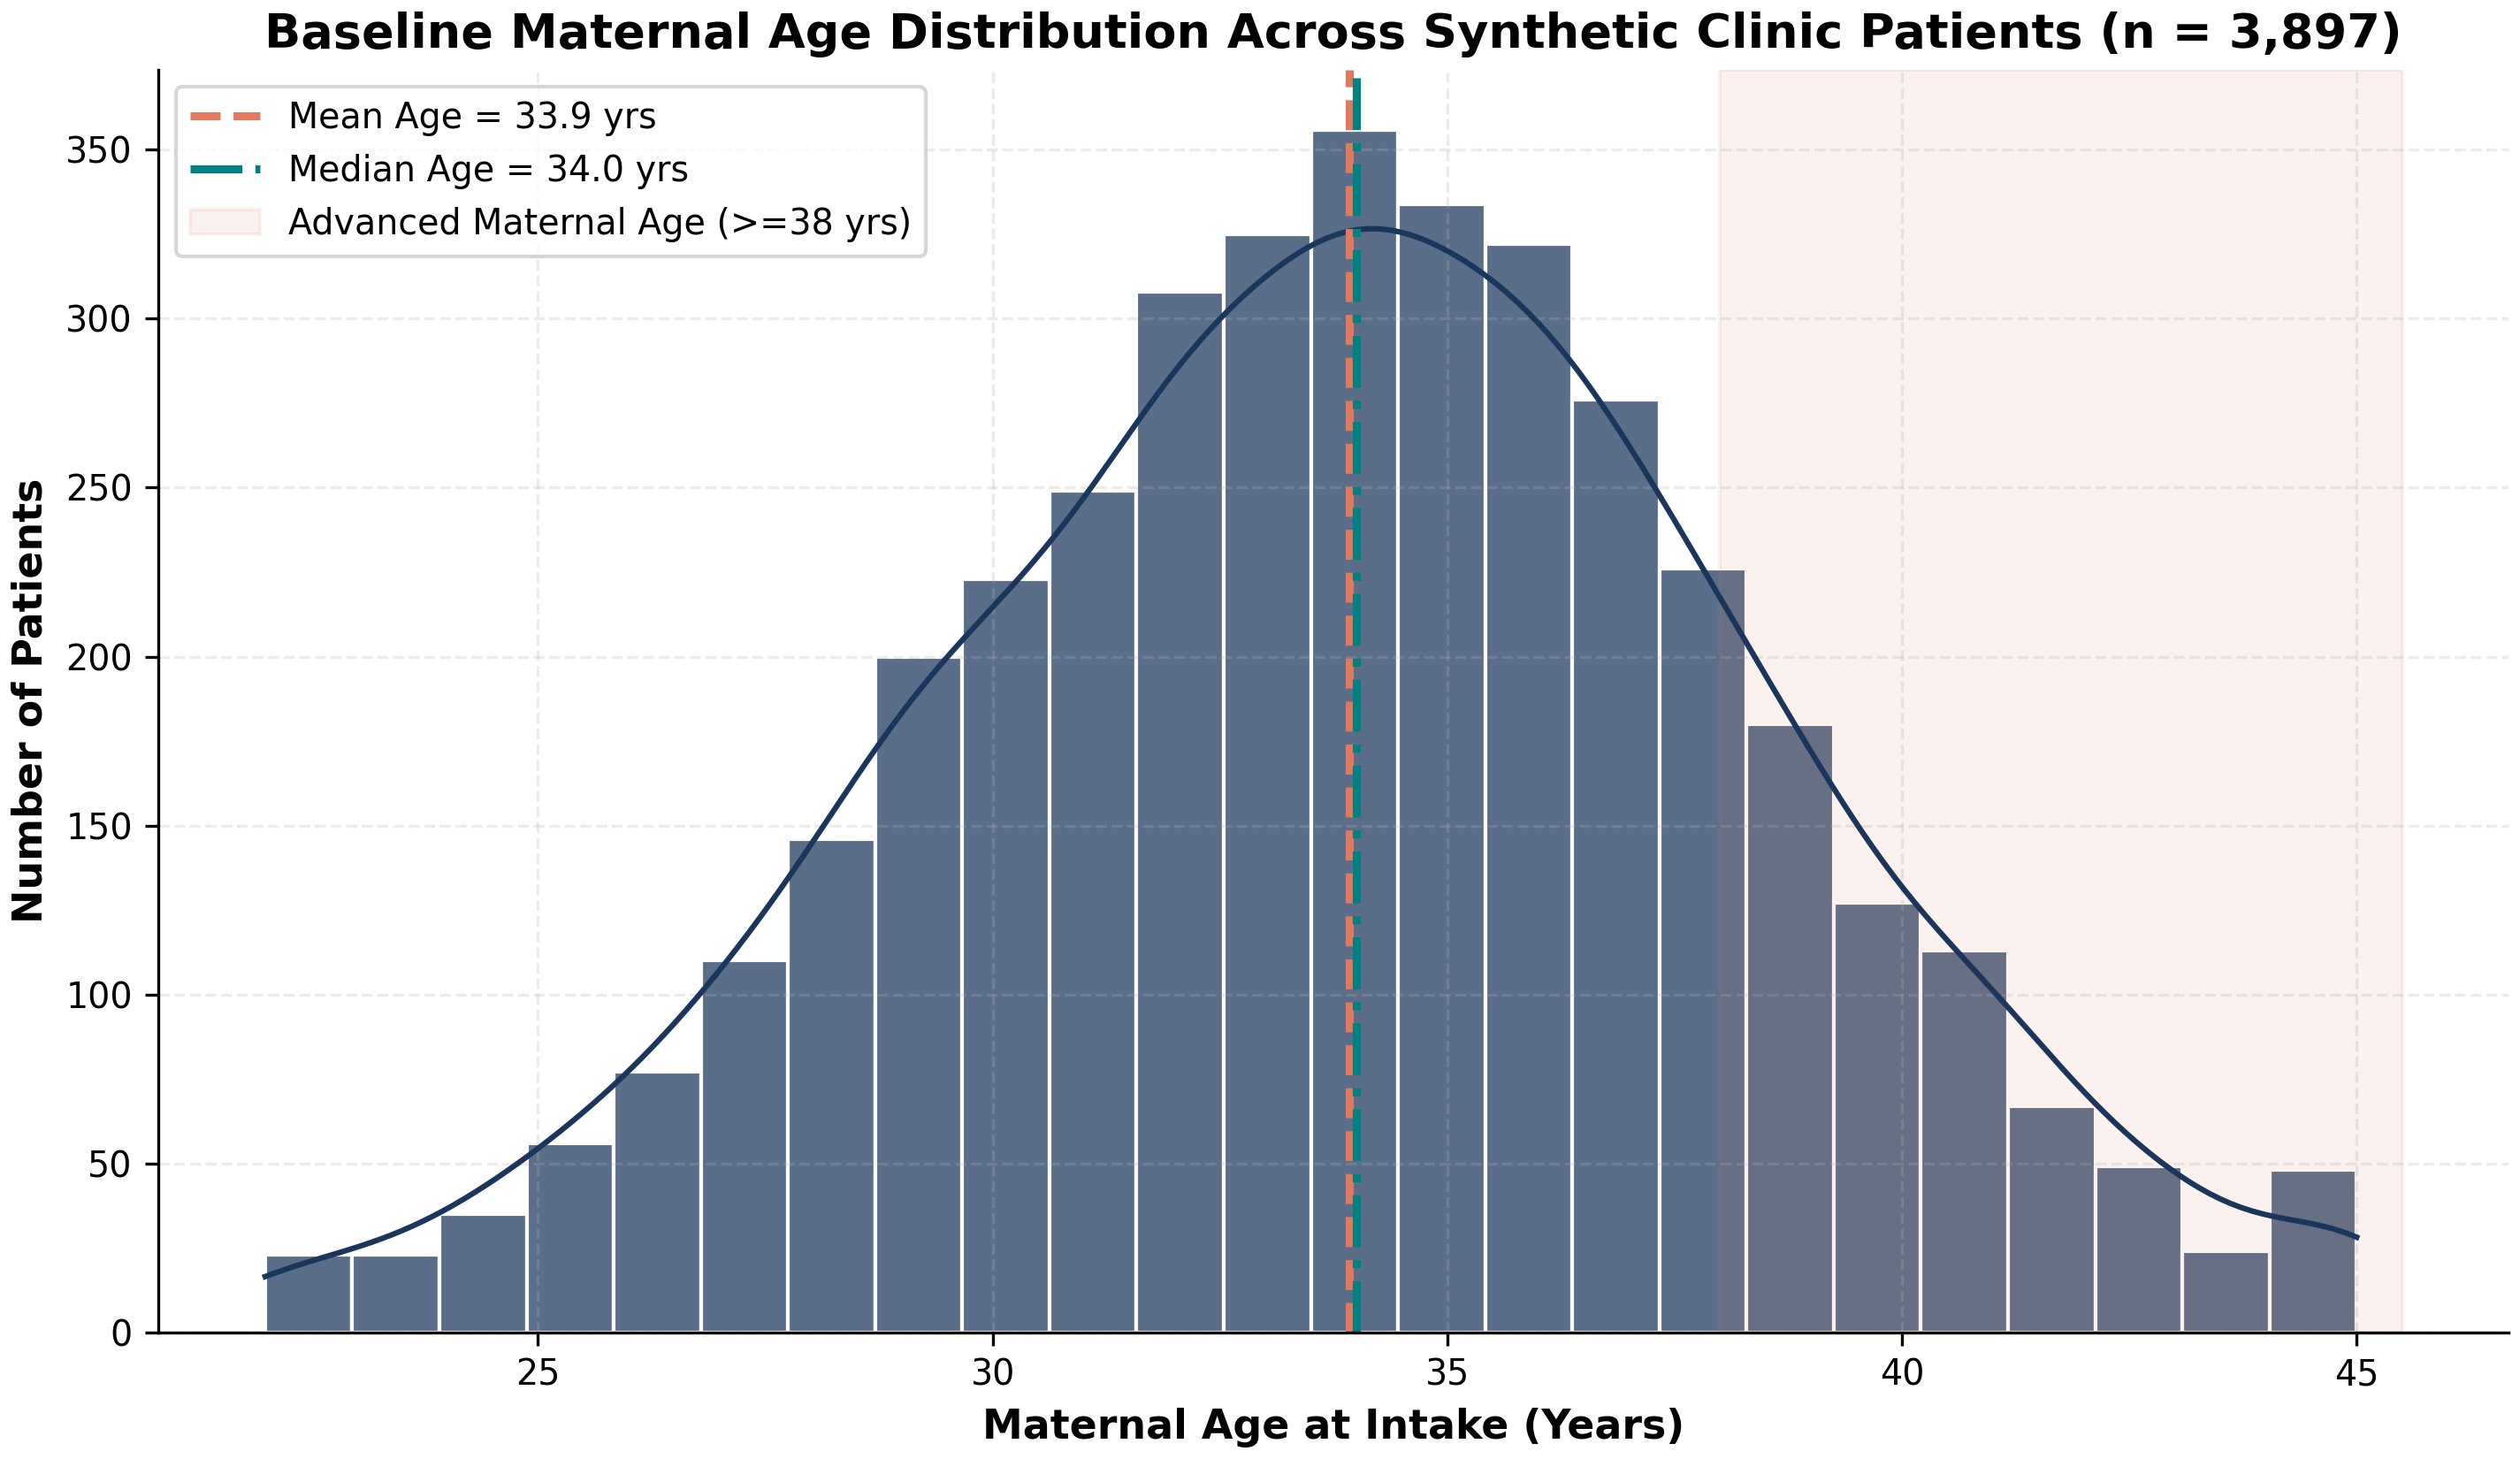

age_group_vs_clinical_pregnancy.png


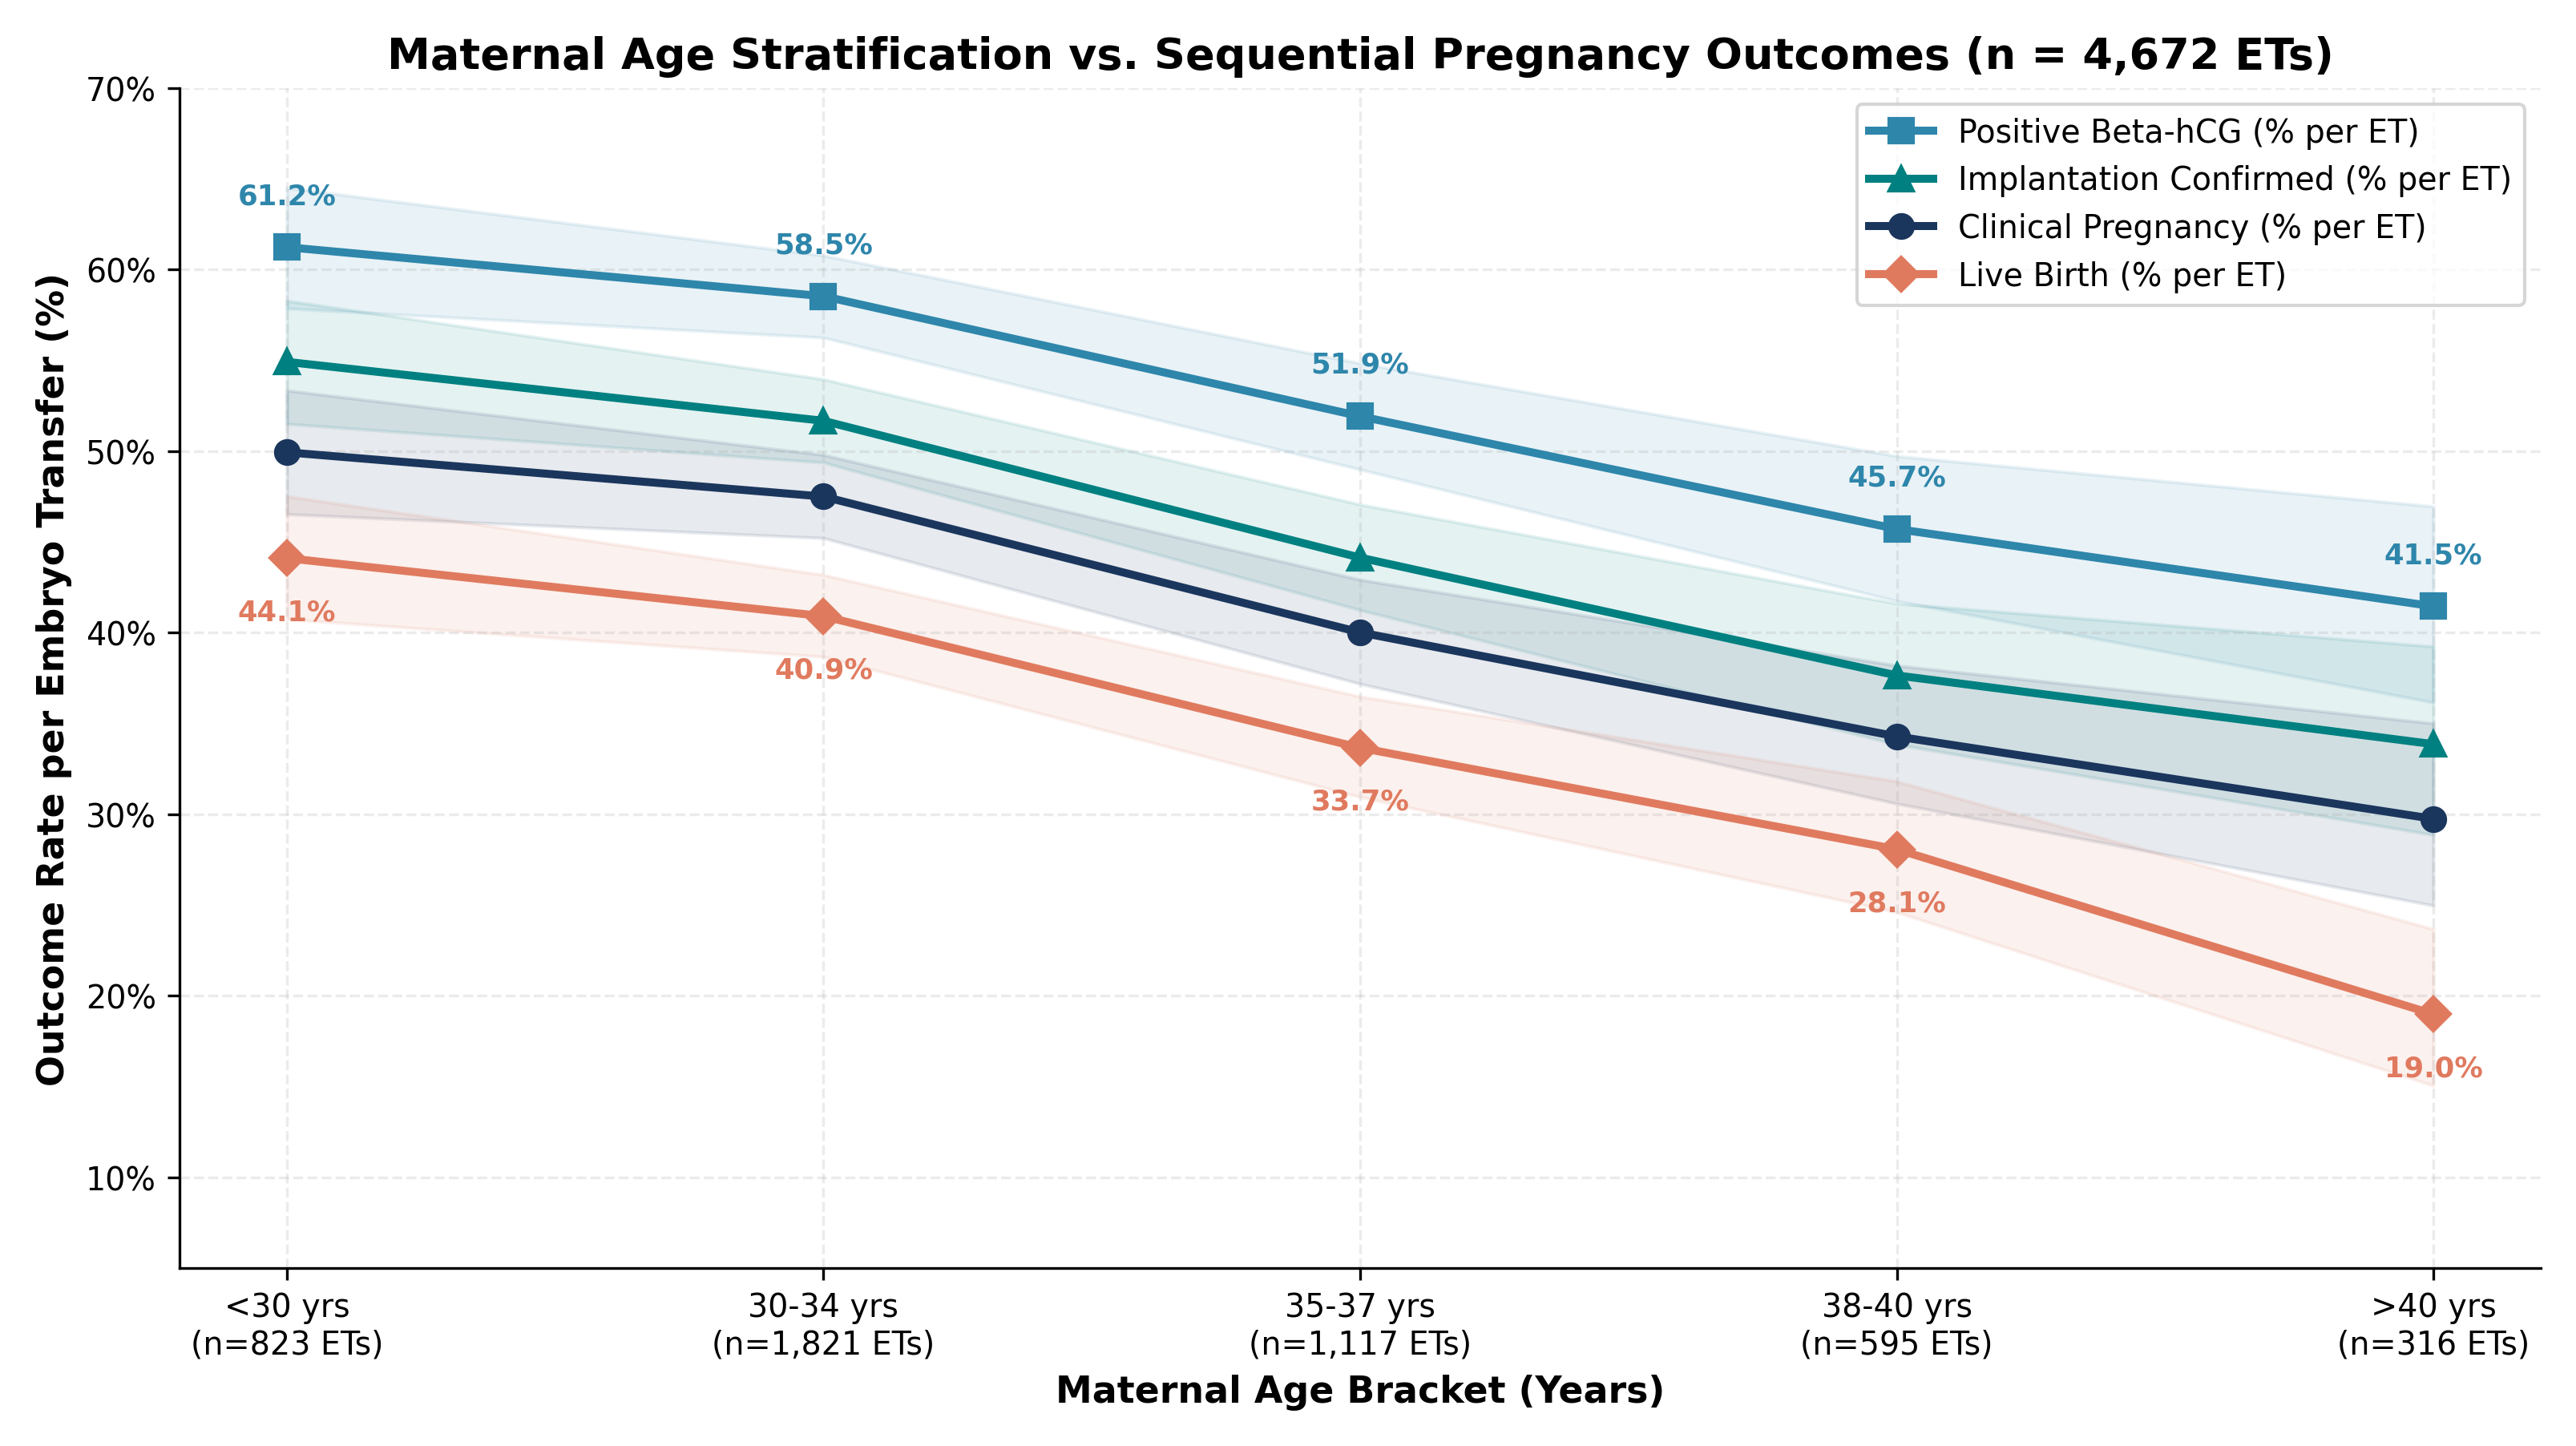

bmi_distribution.png


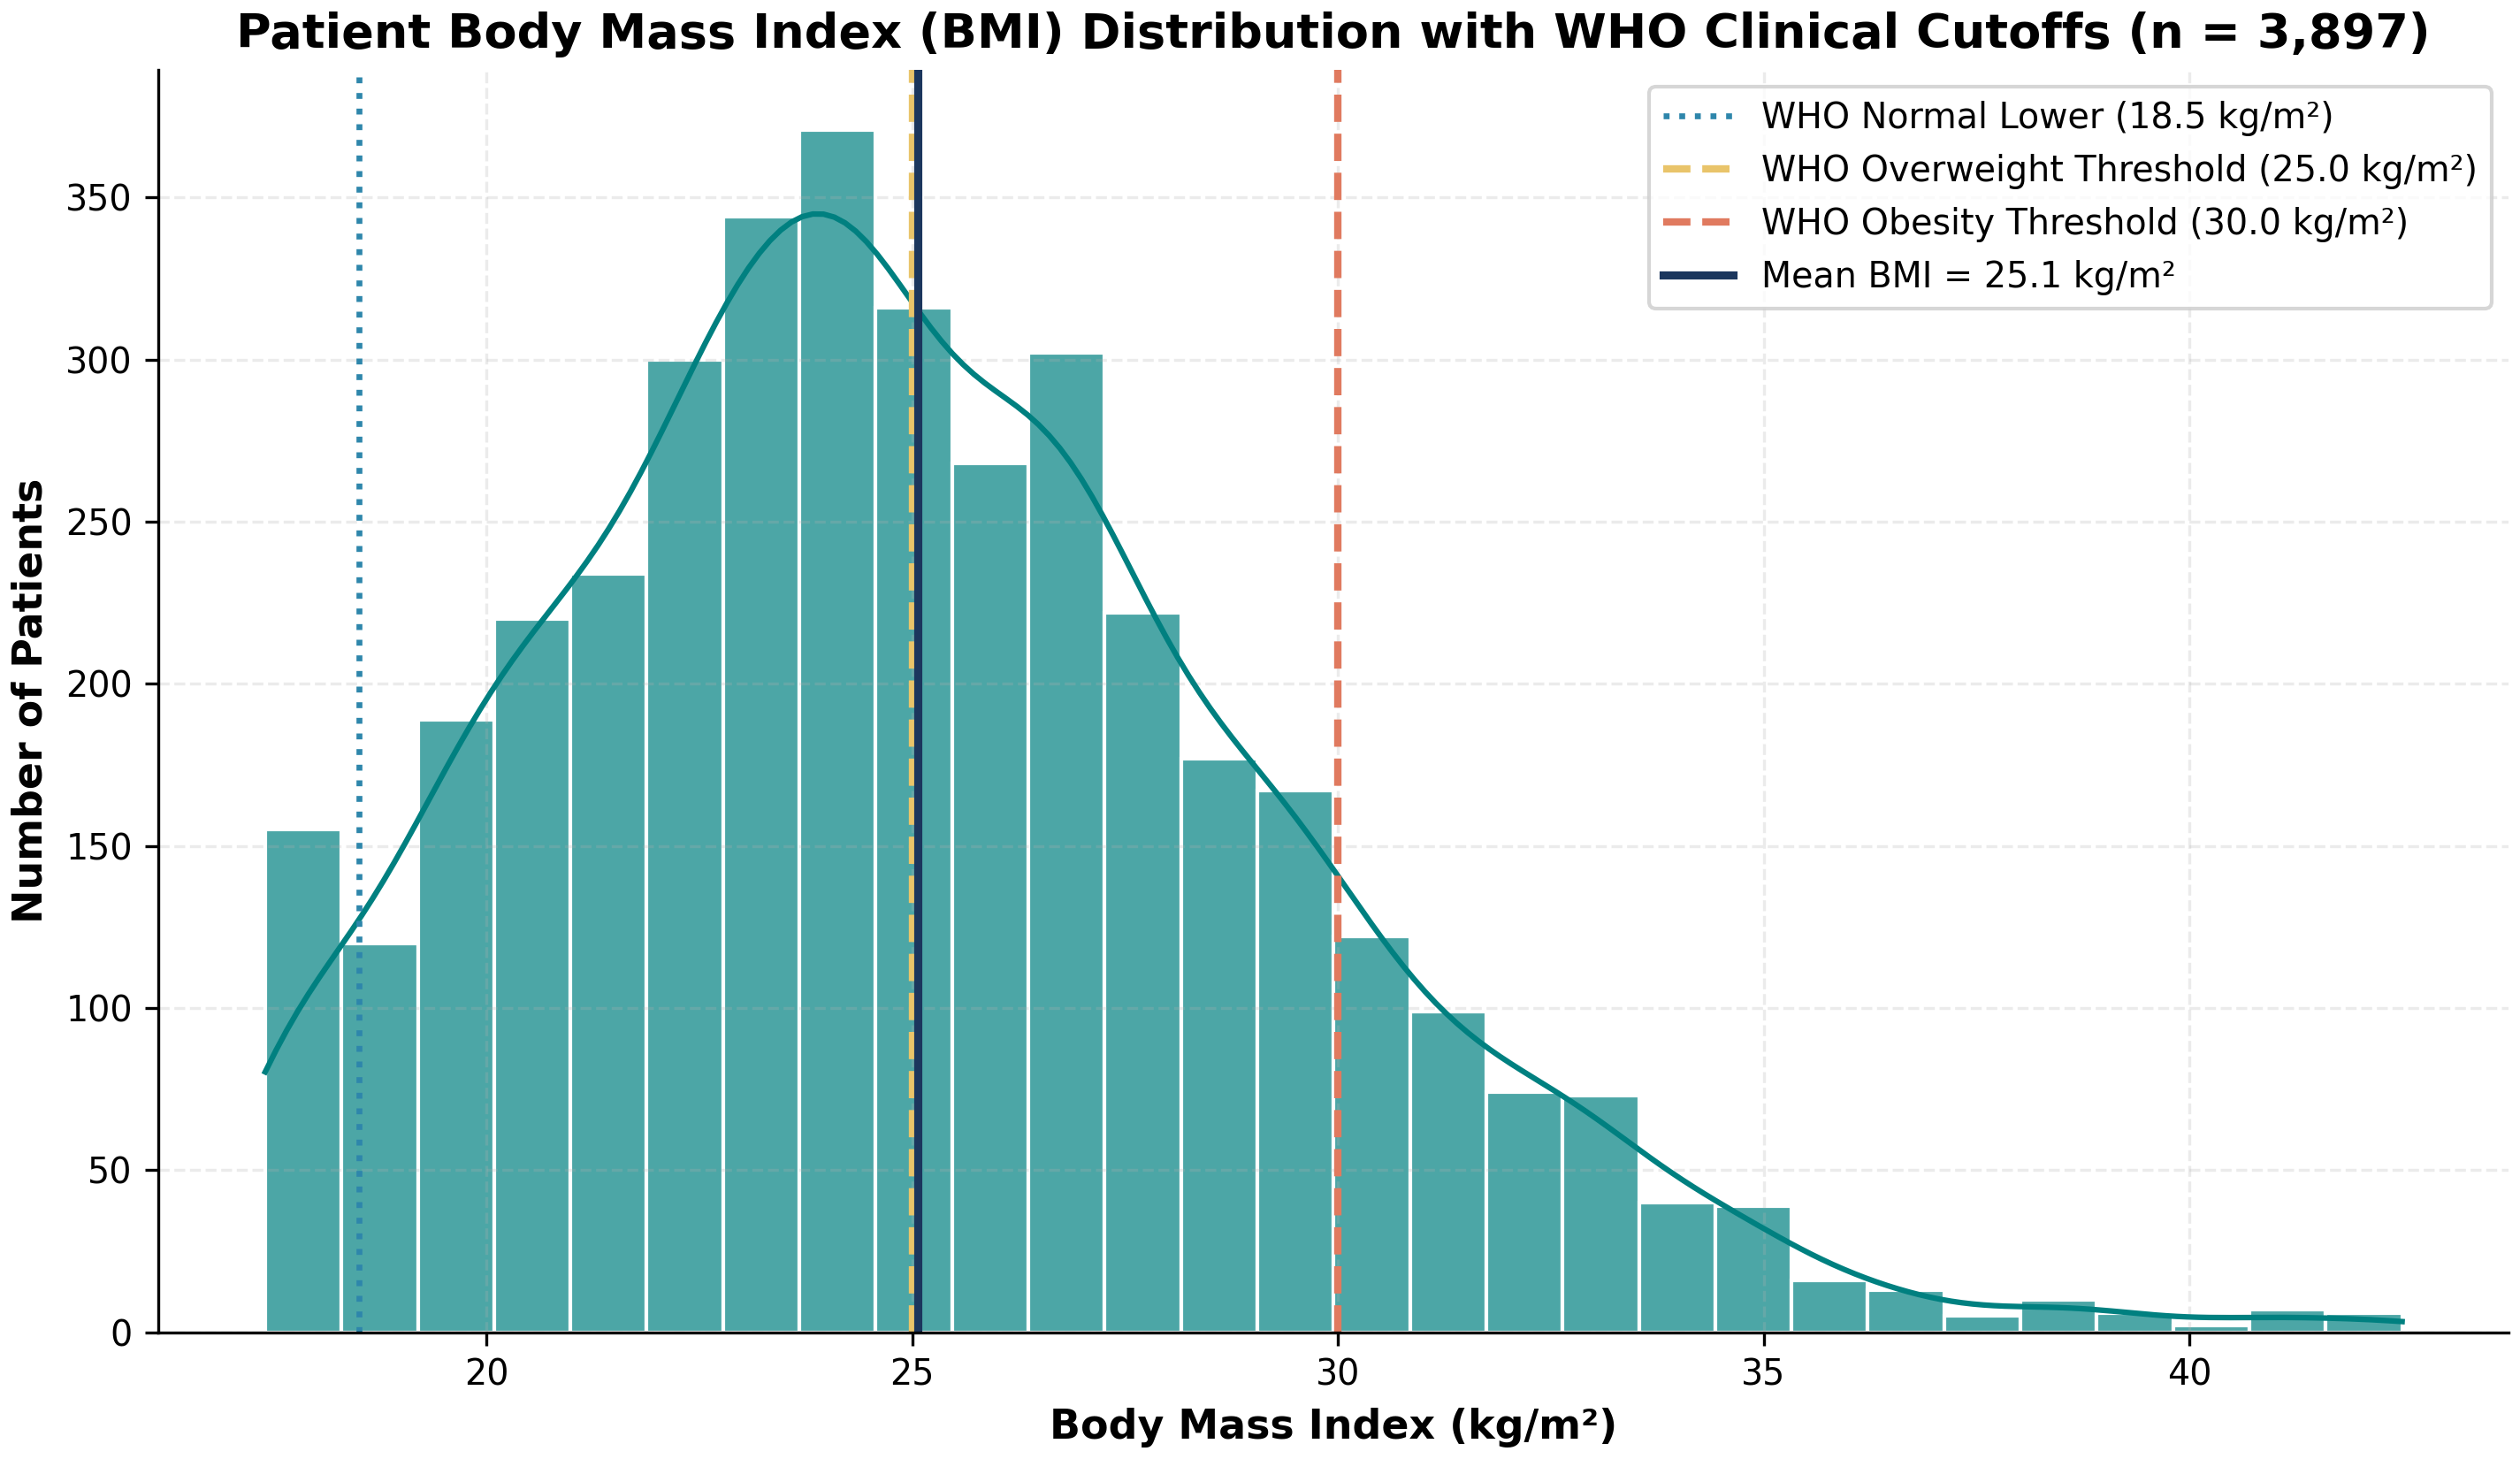

correlation_heatmap.png


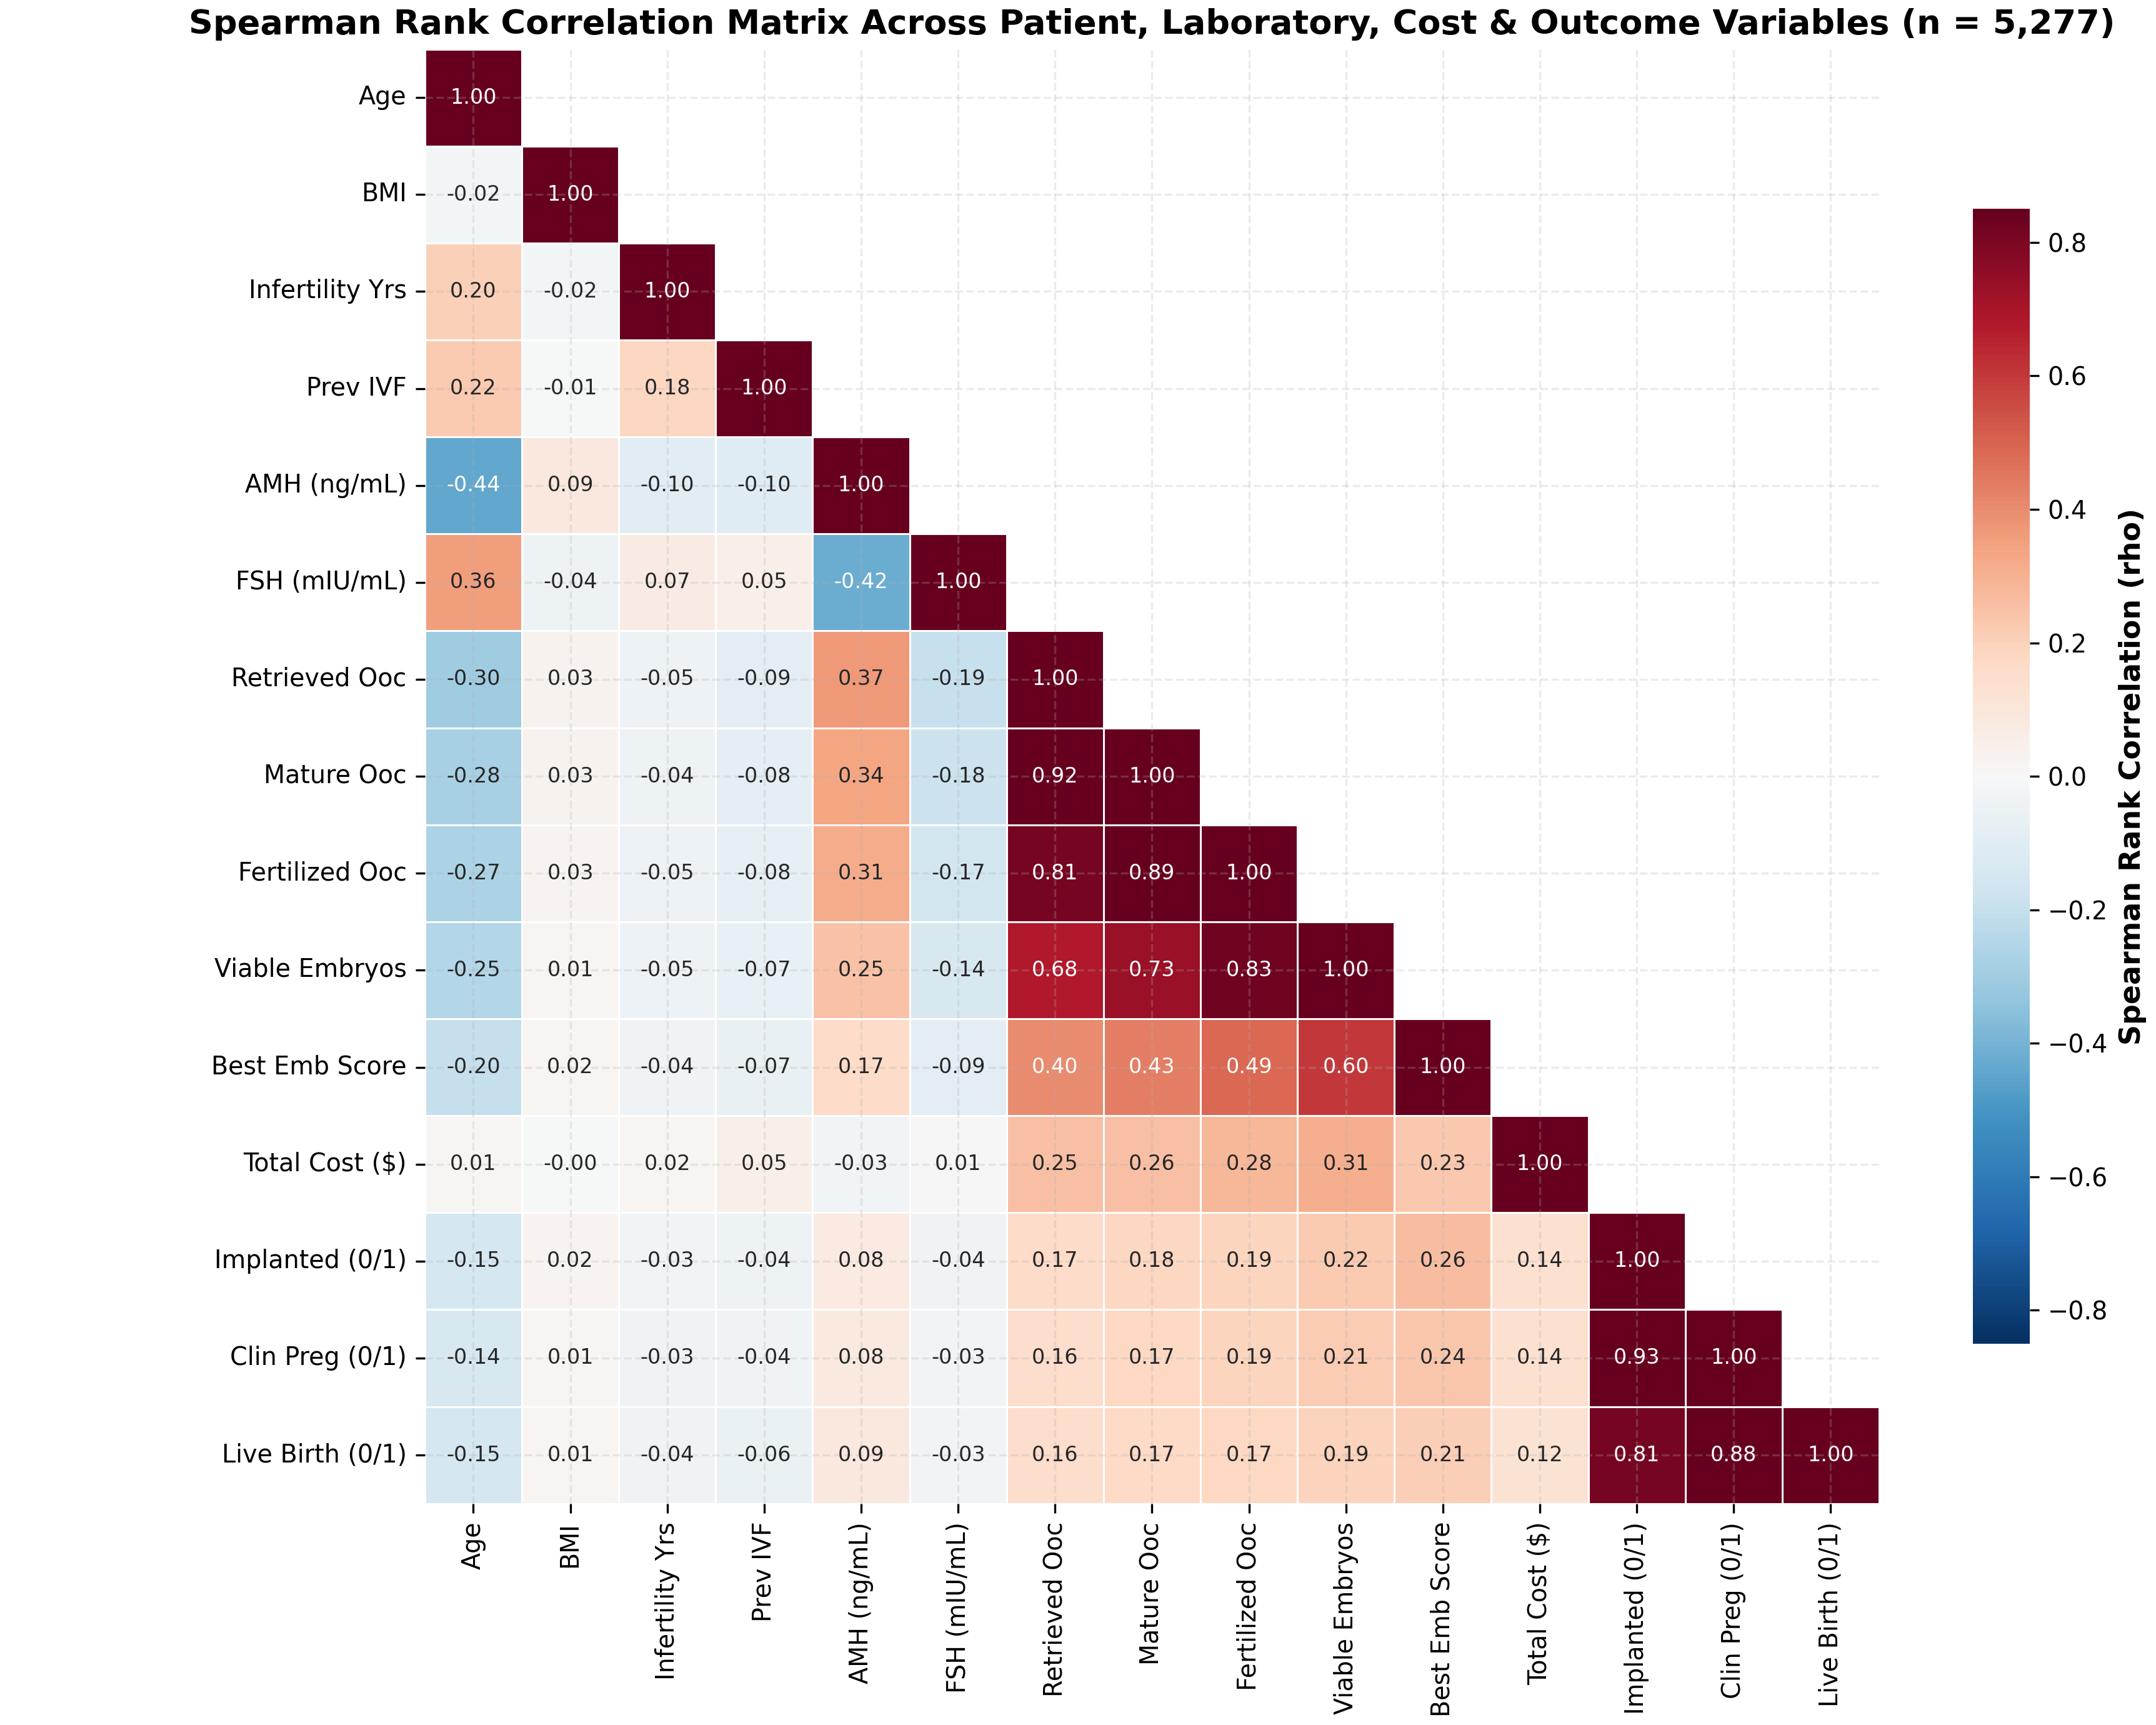

day3_vs_day5_outcomes.png


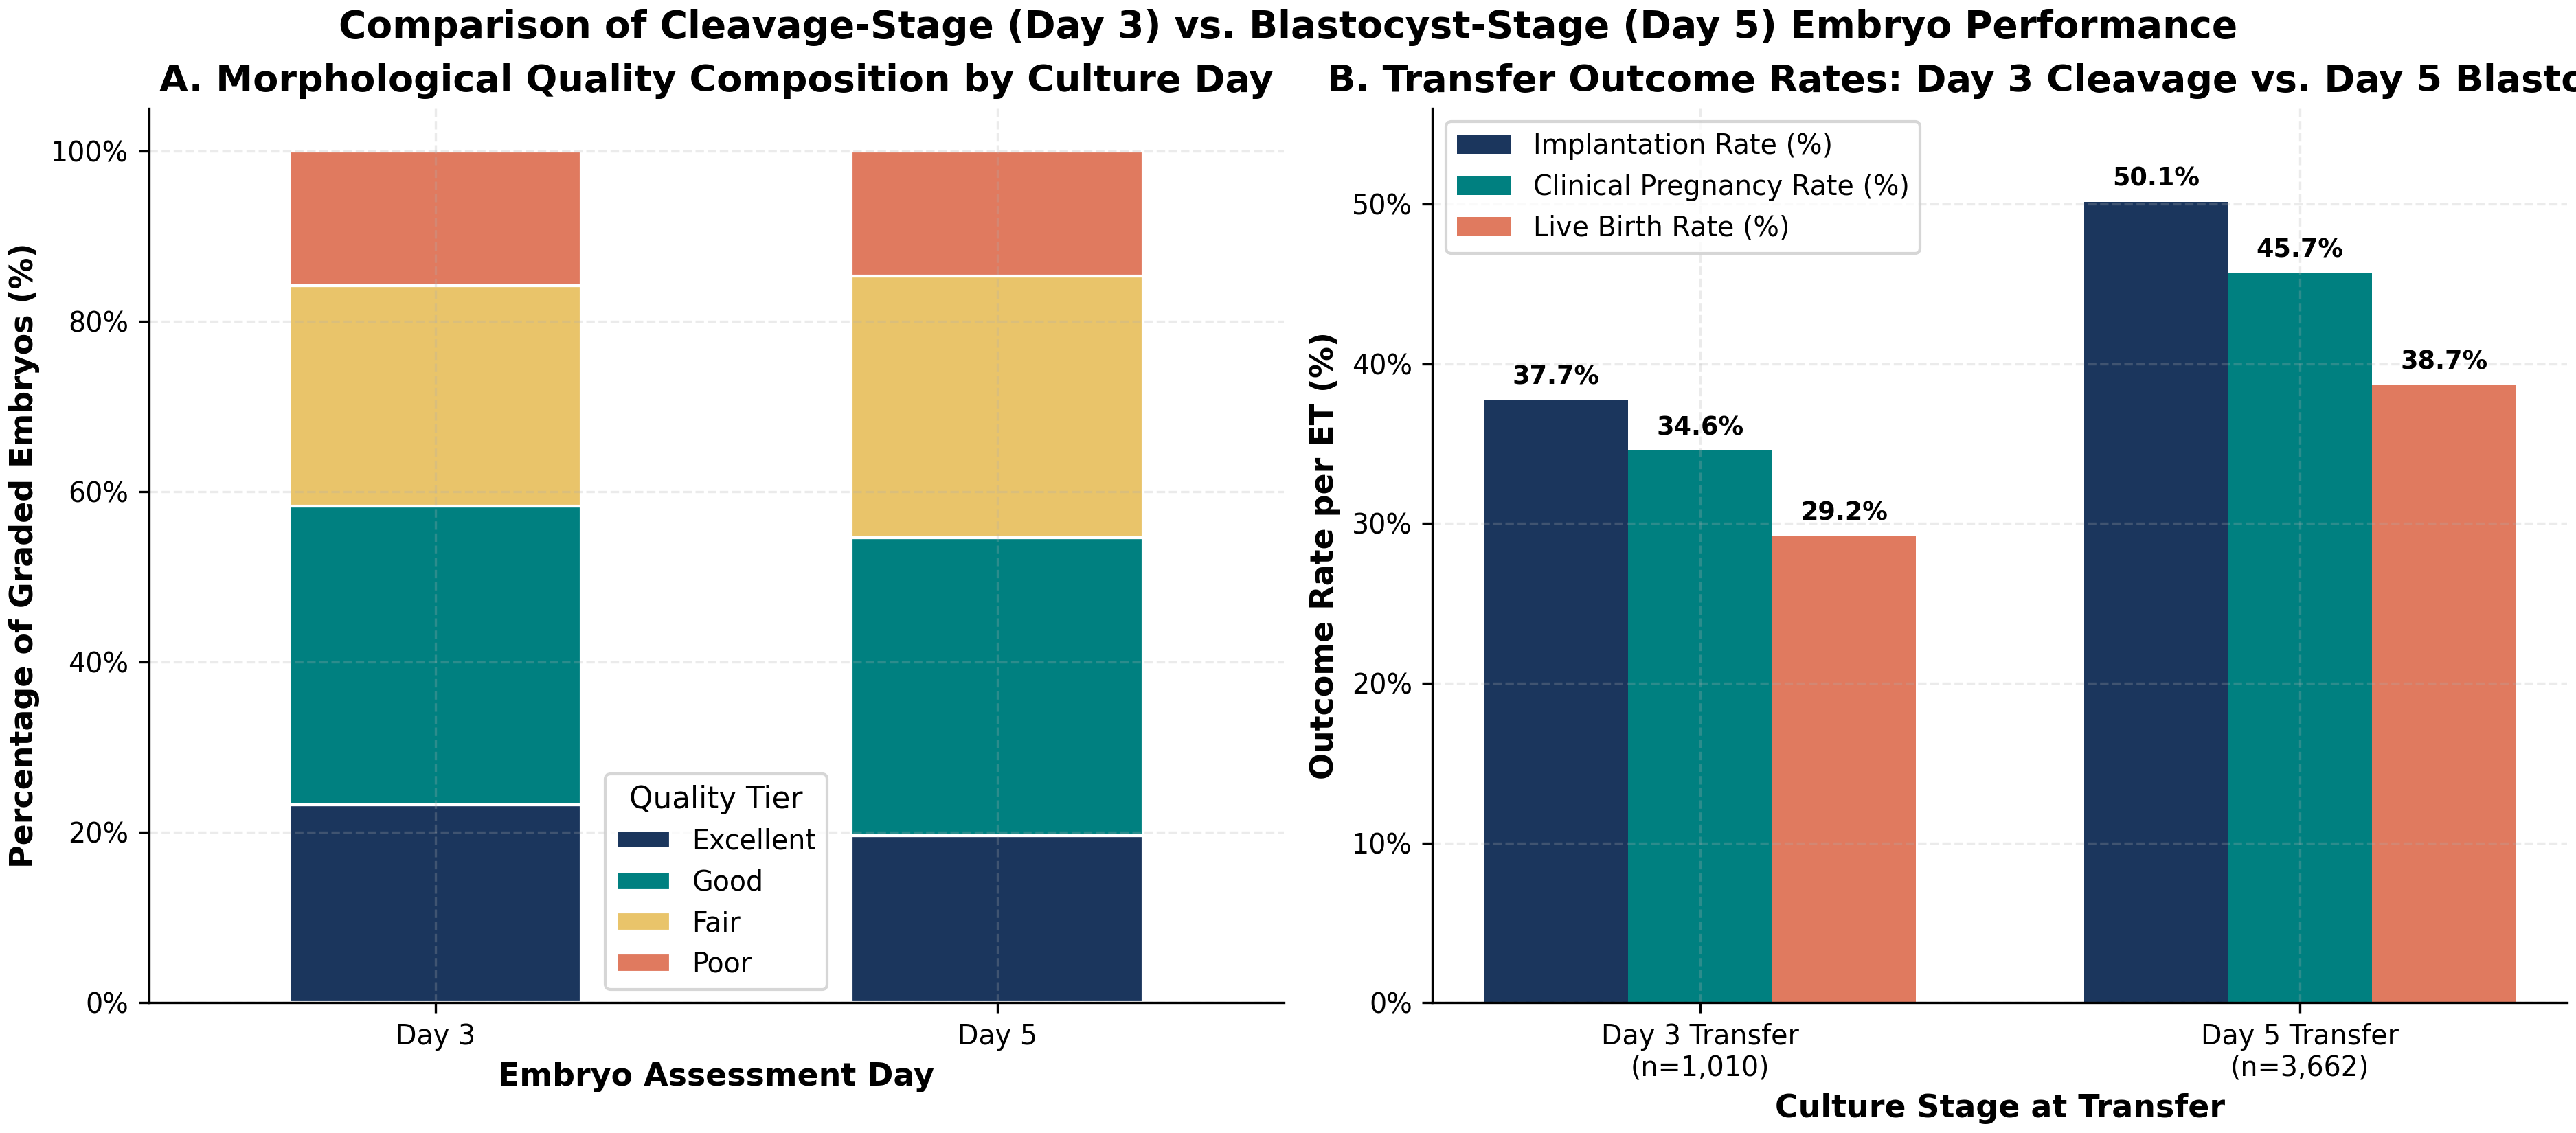

embryo_grading_comparison.png


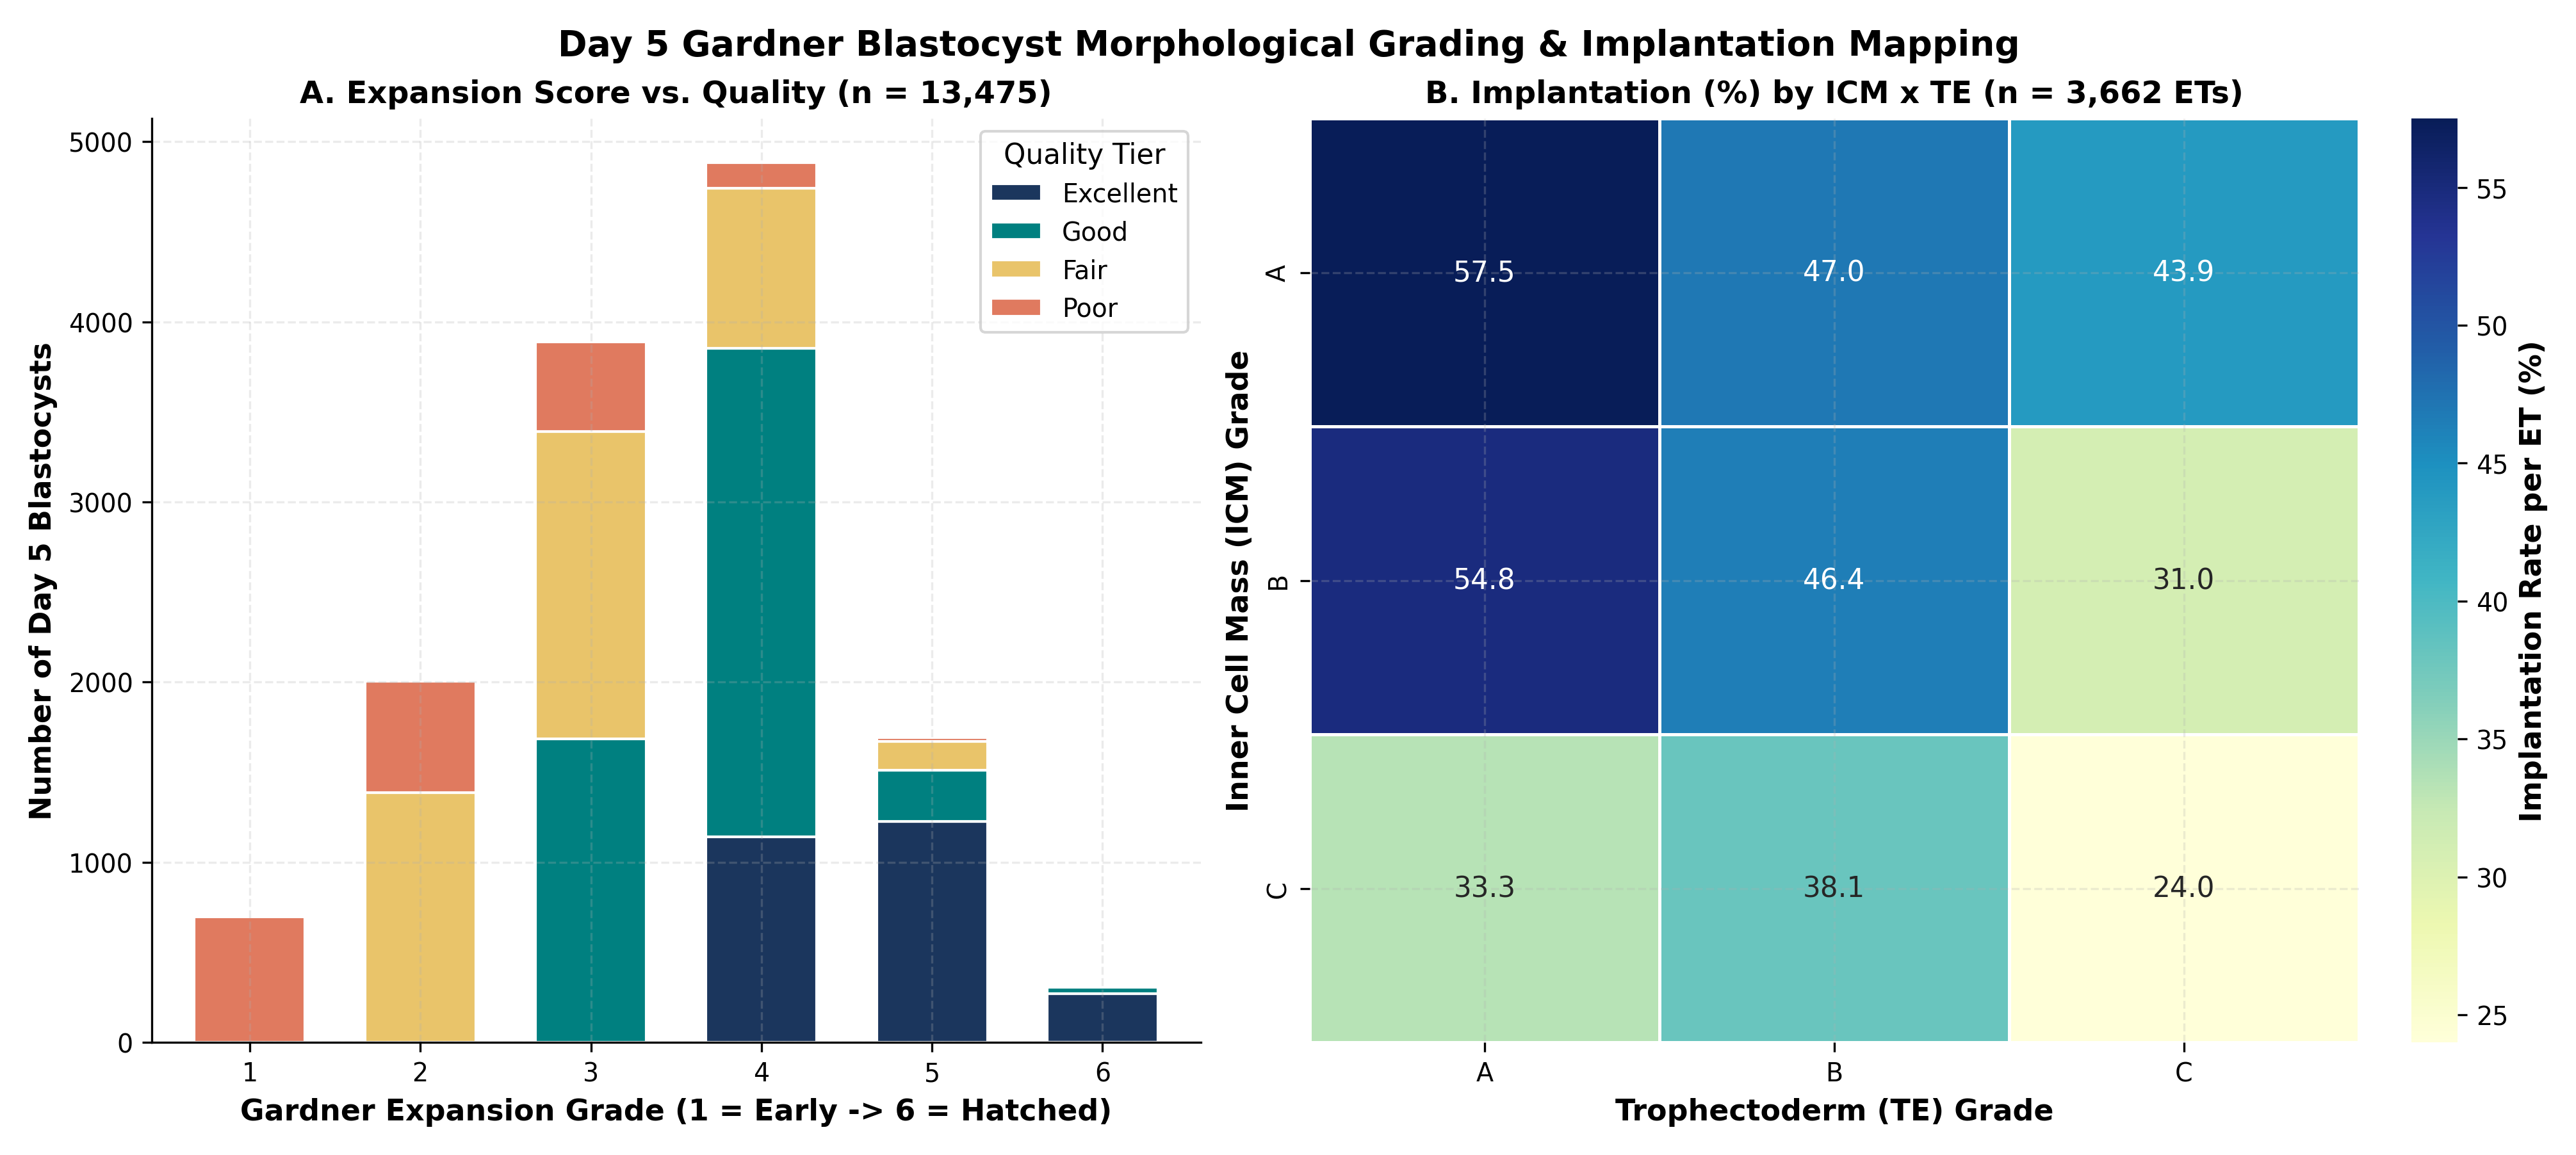

embryo_quality.png


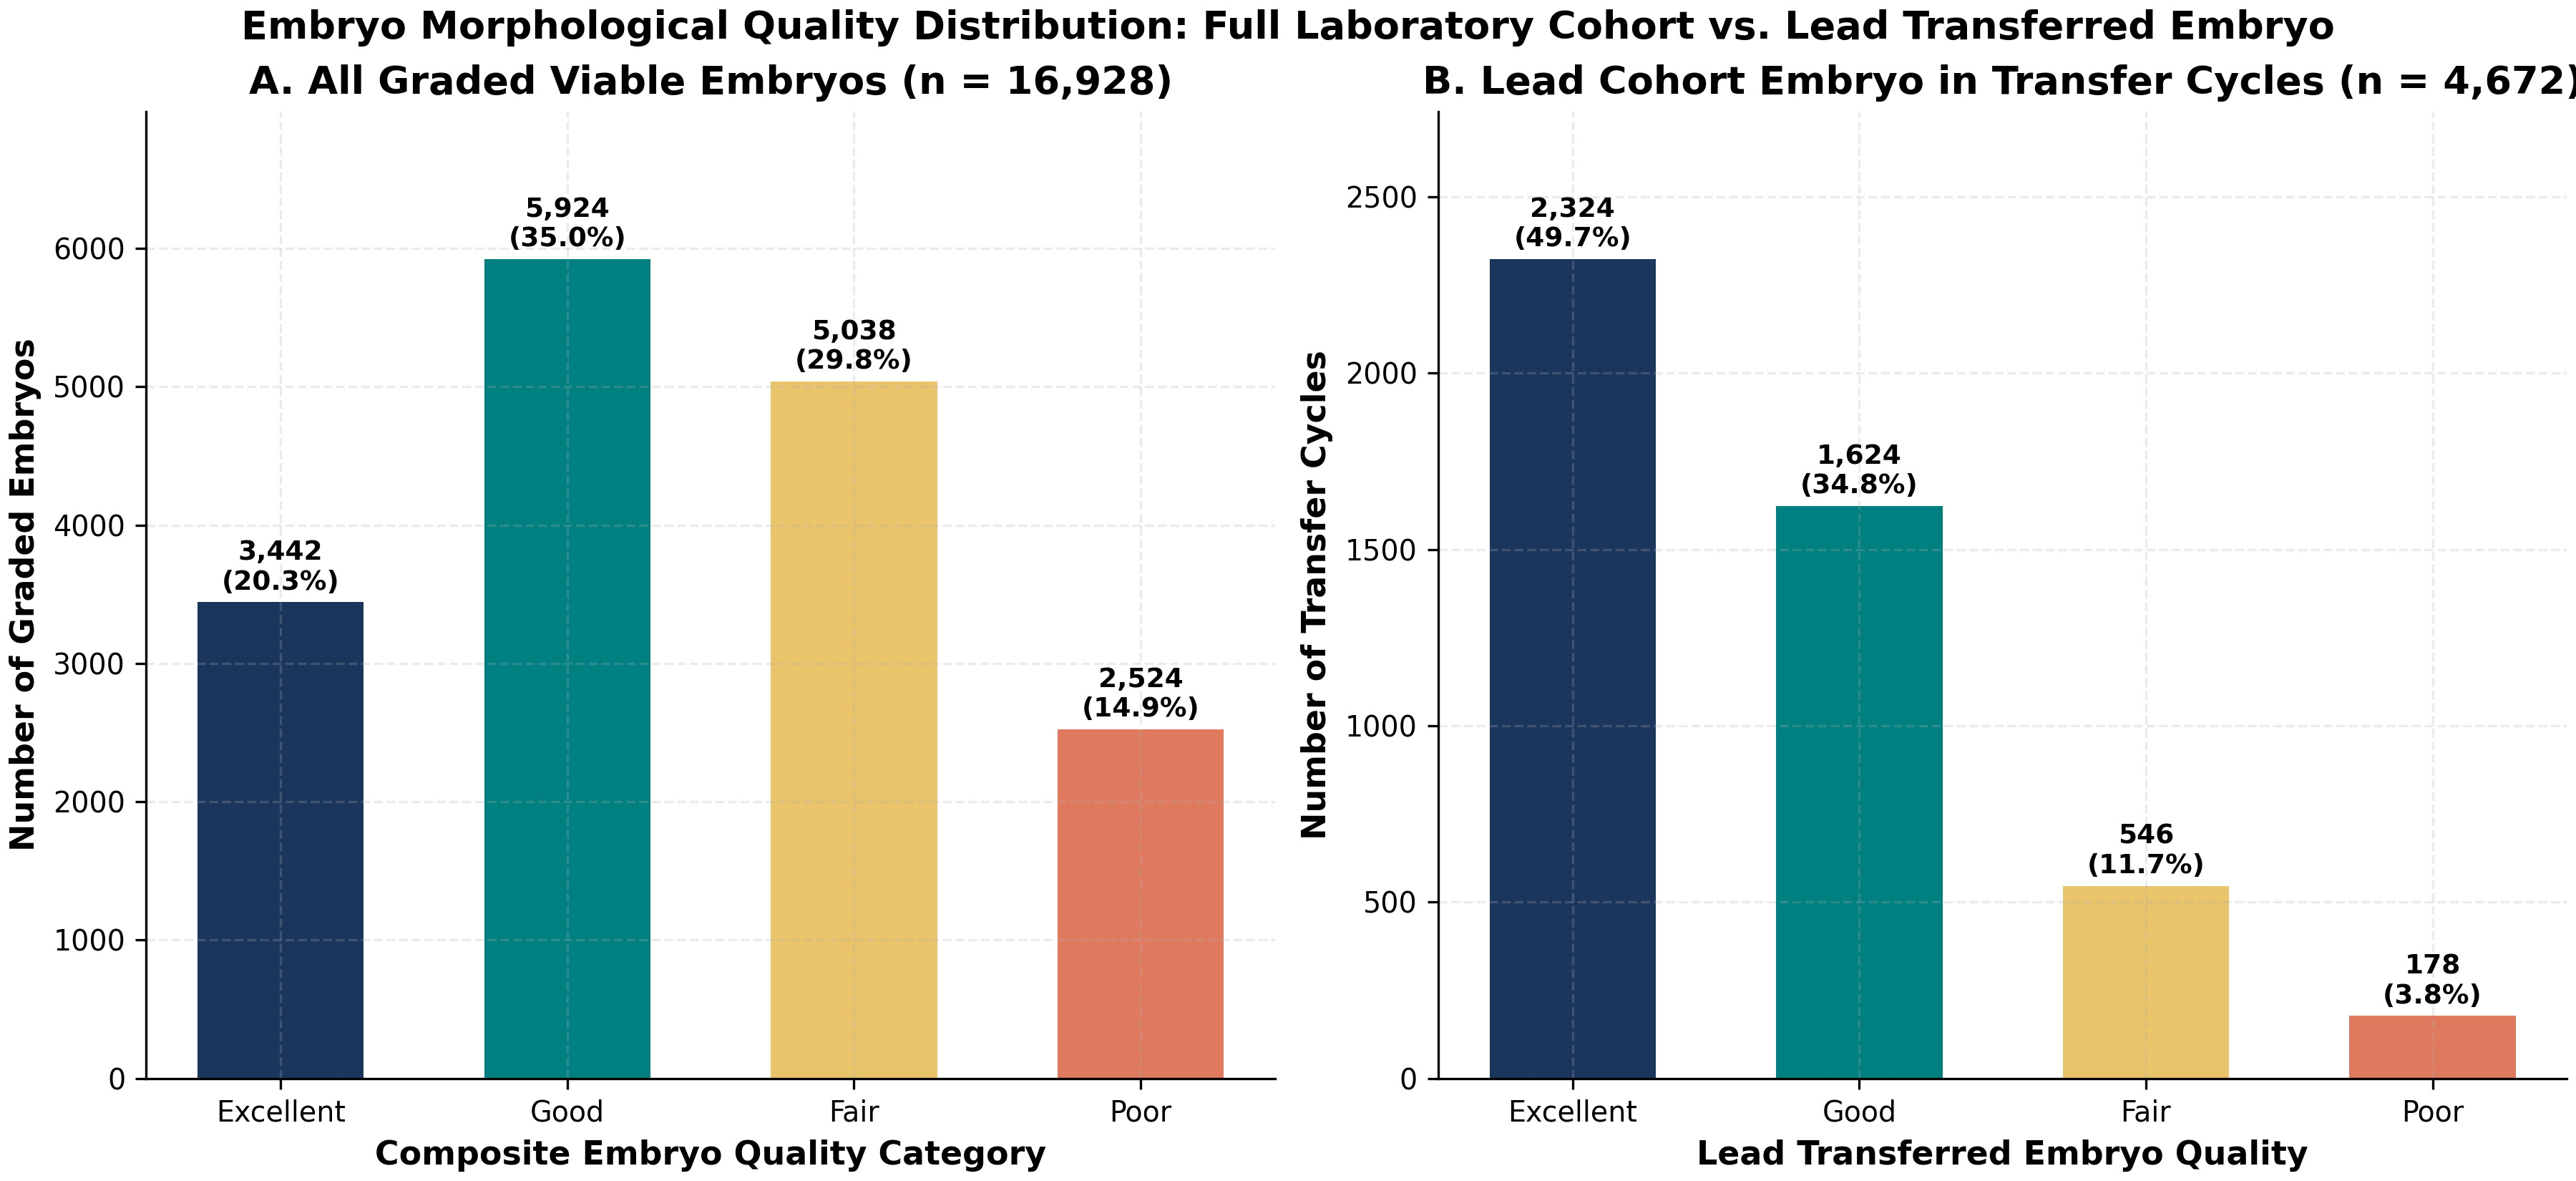

implantation_analysis.png


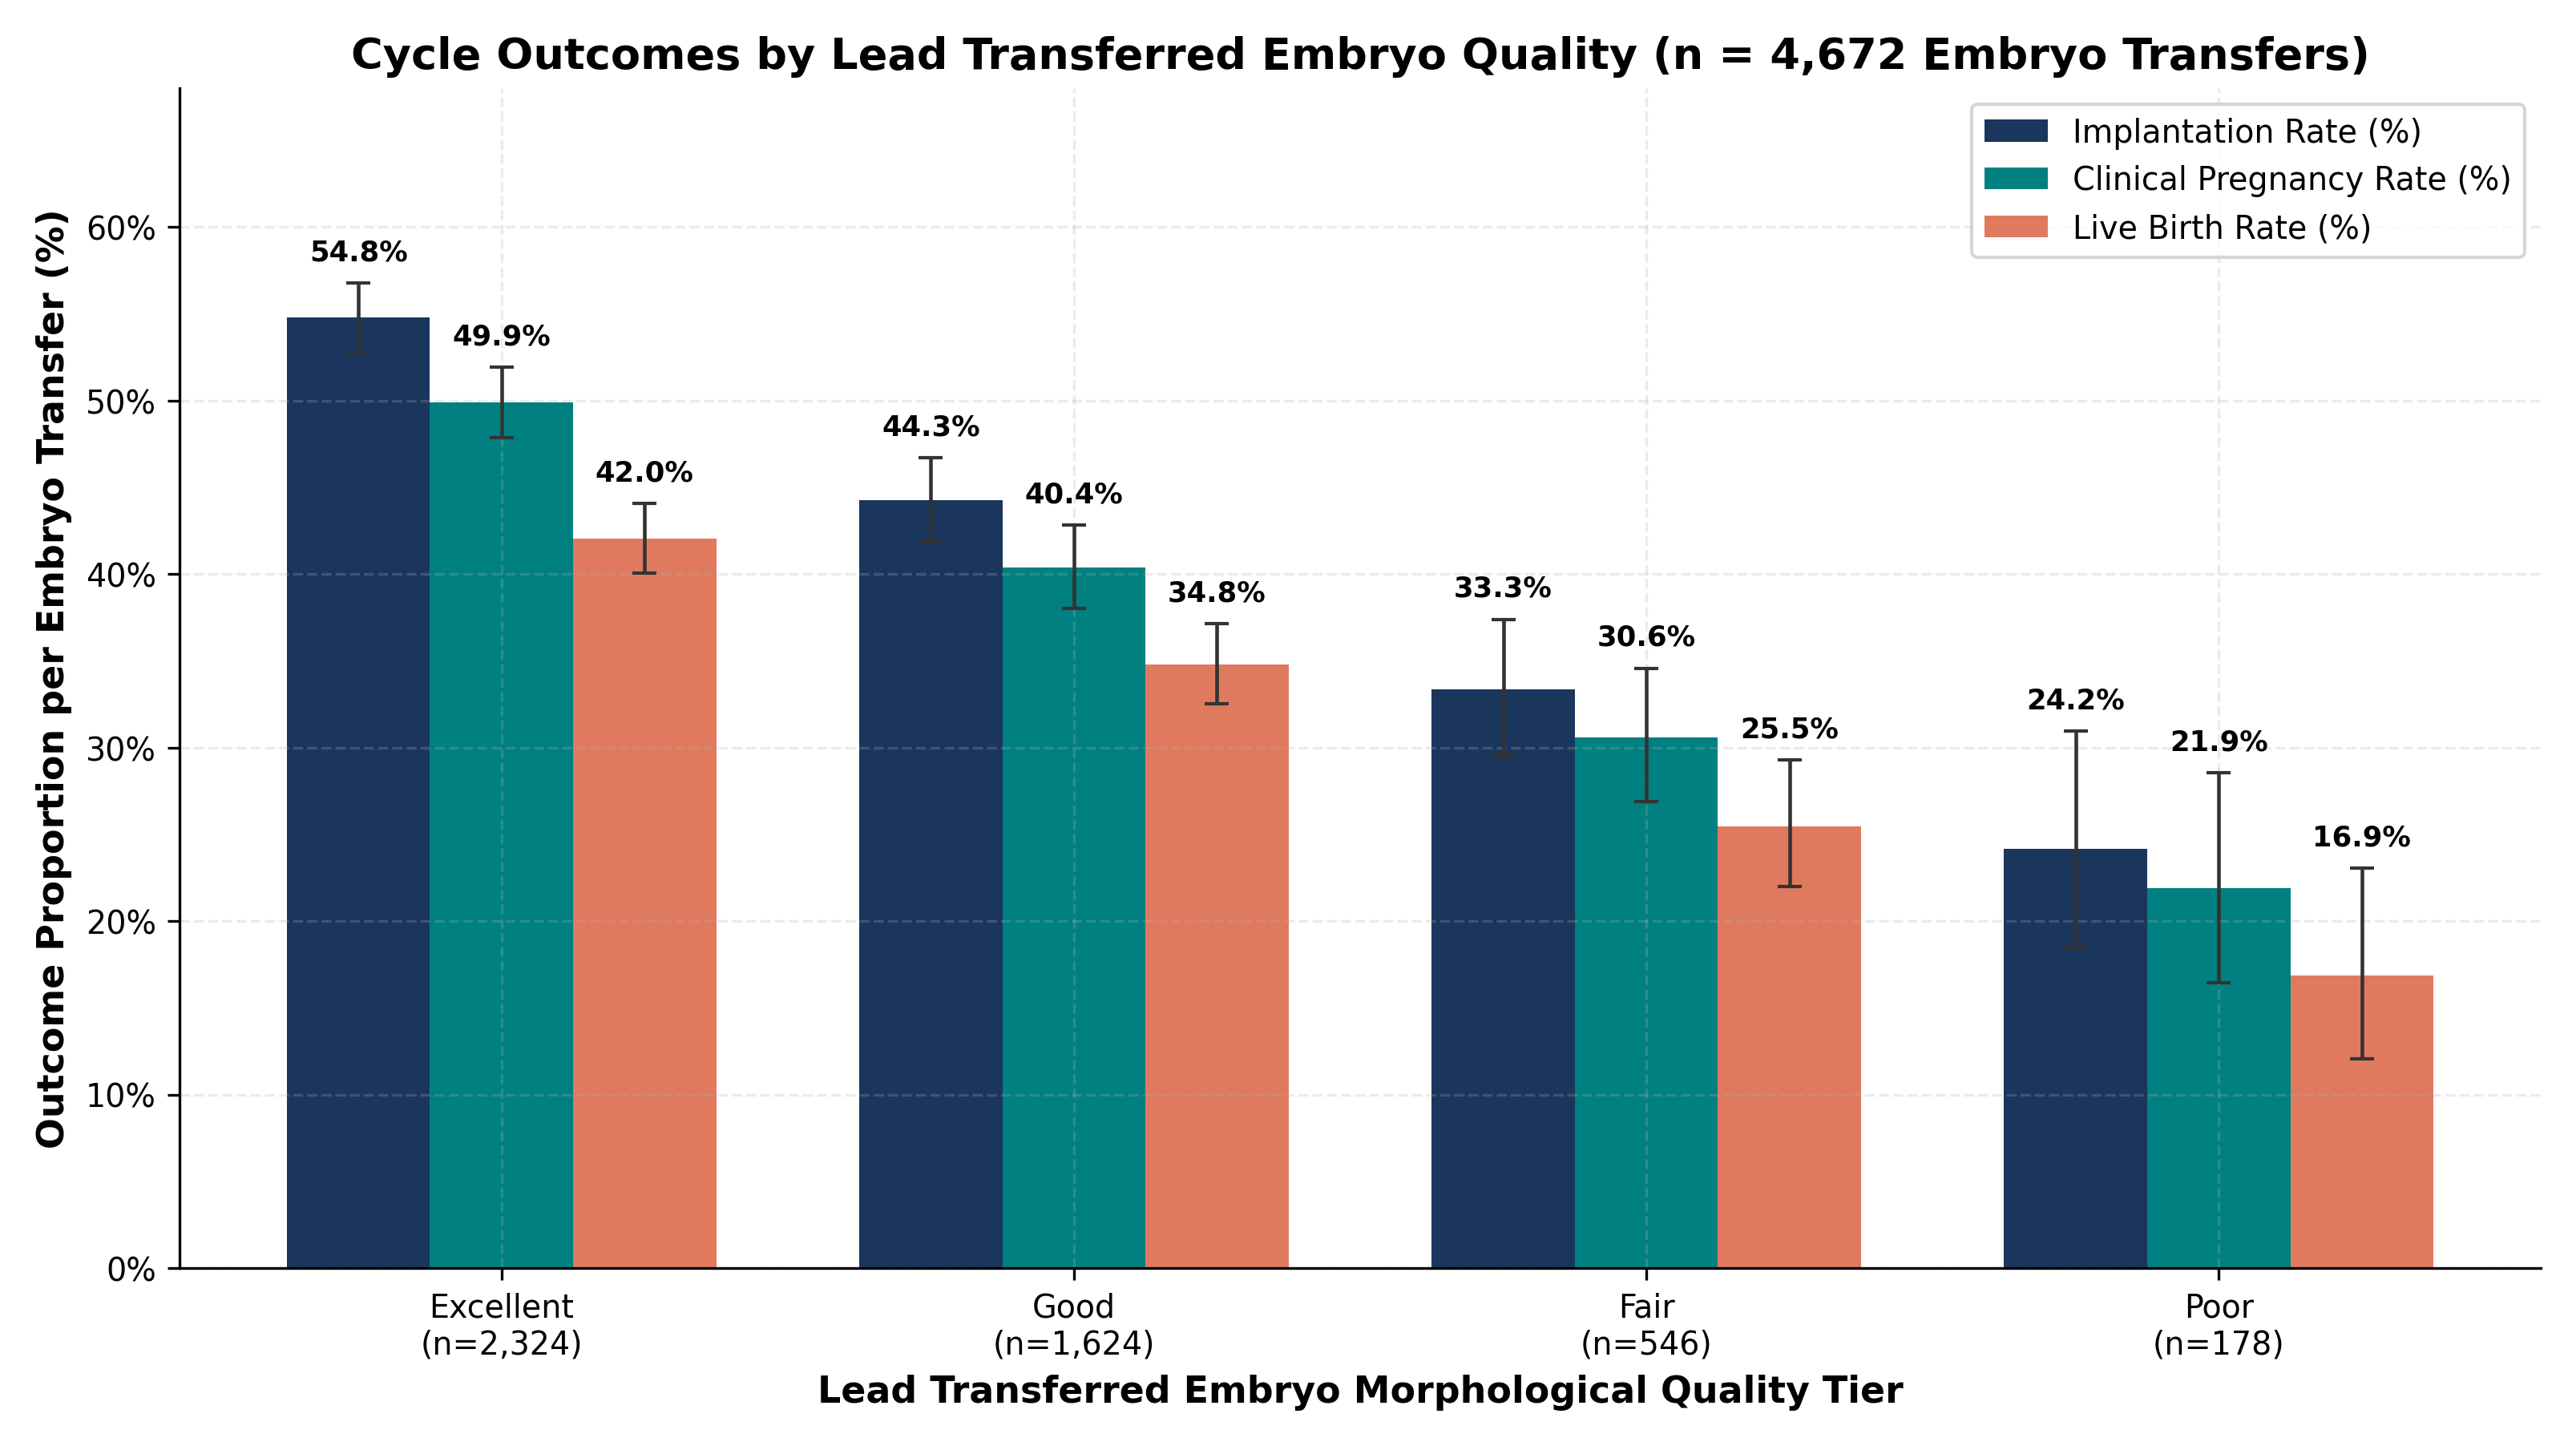

infertility_type_distribution.png


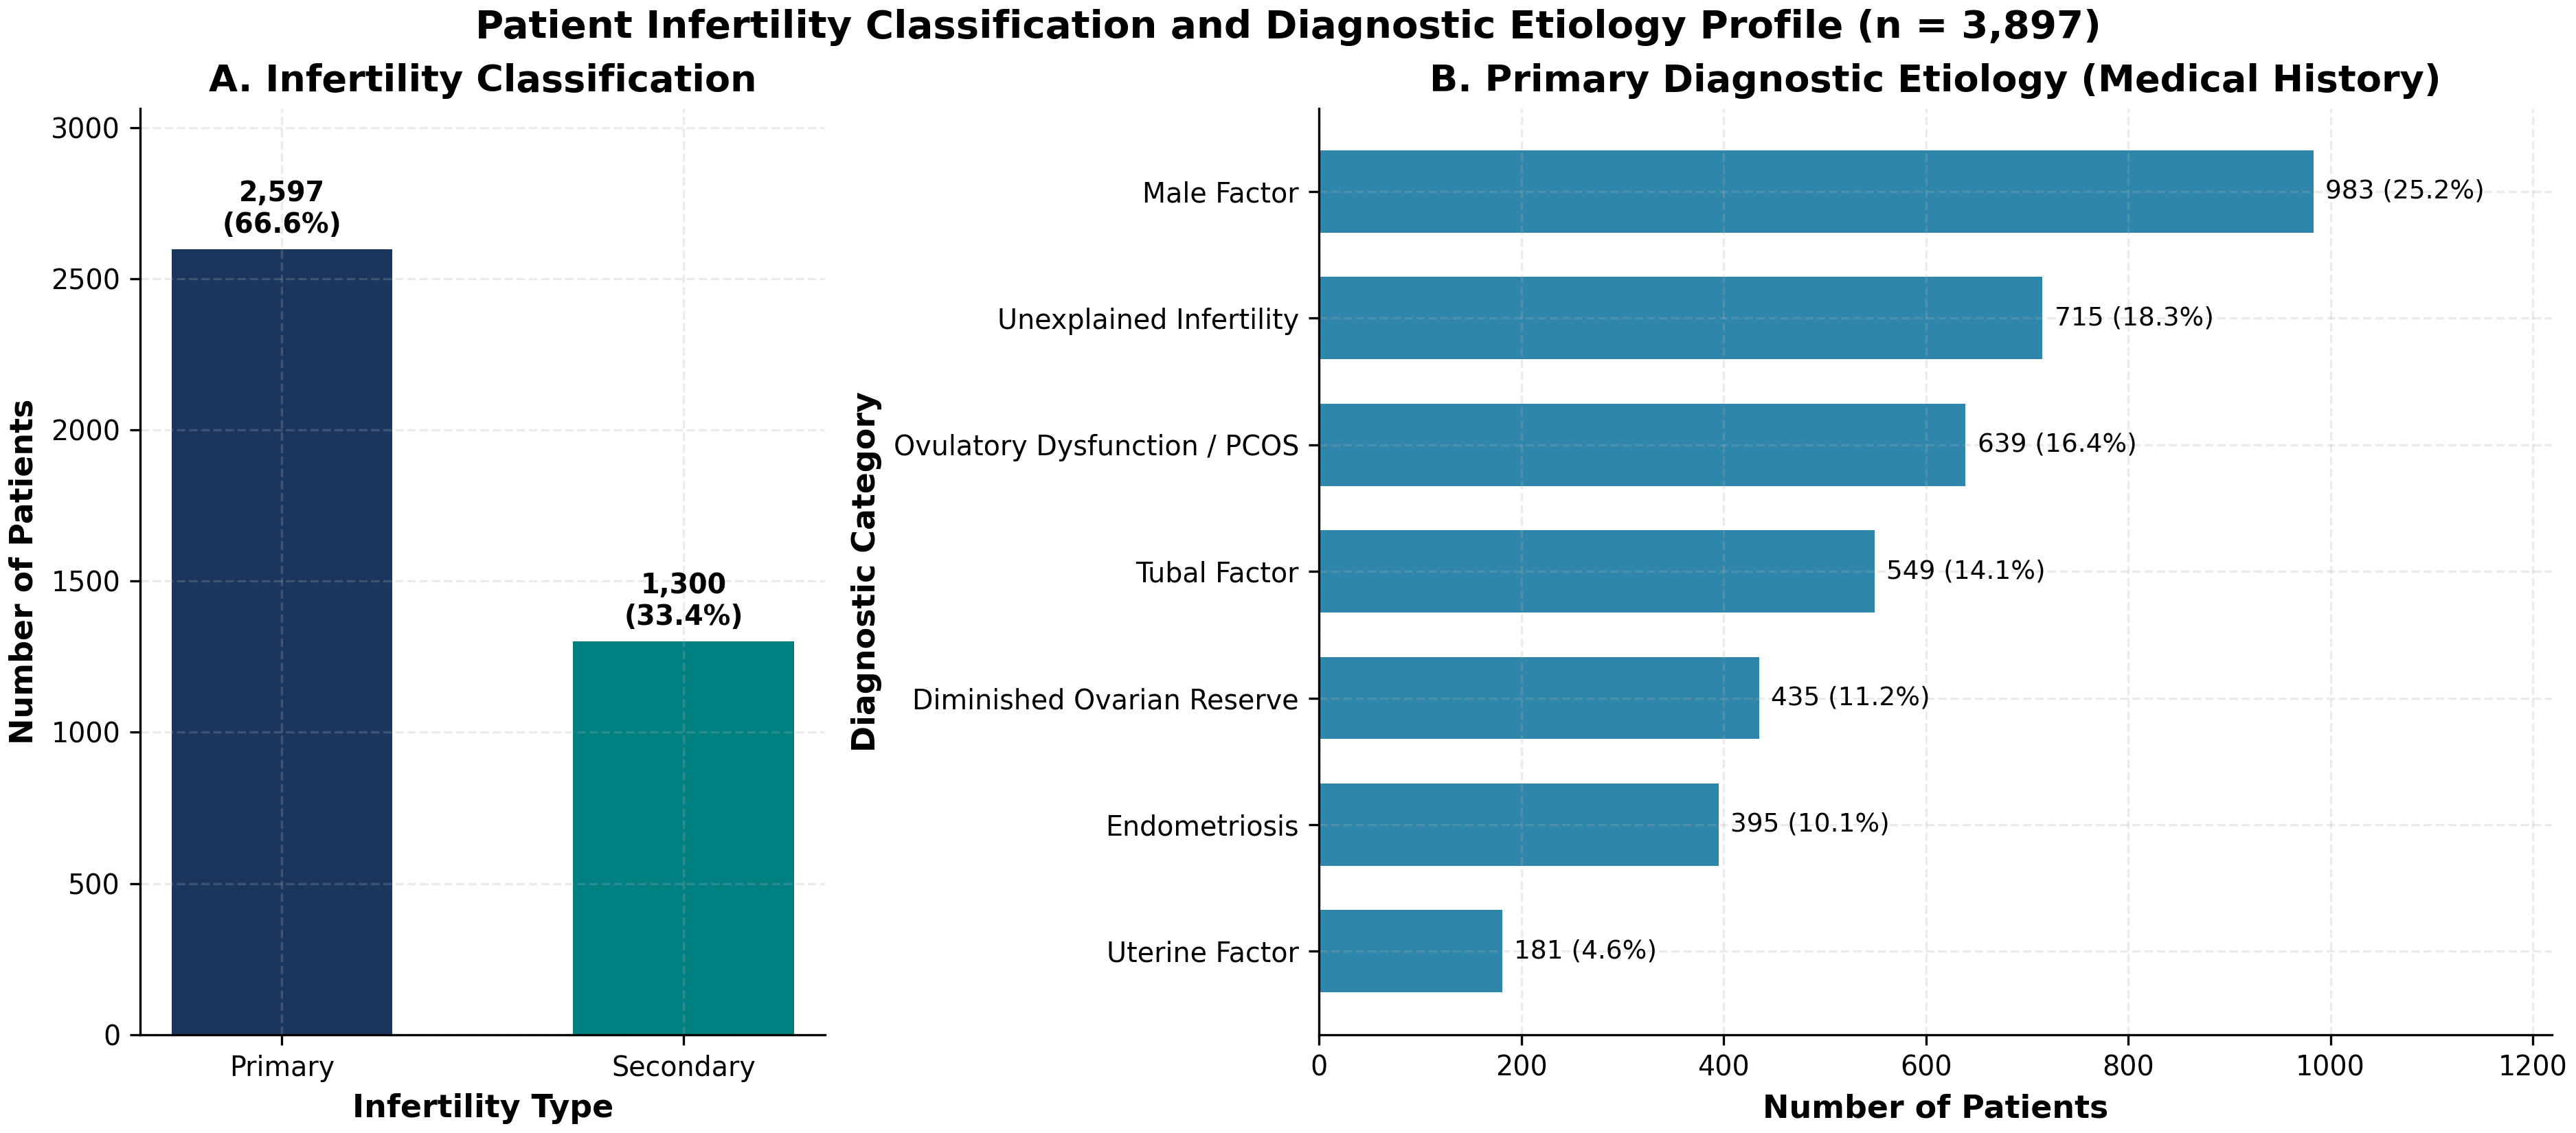

live_birth_outcome_distribution.png


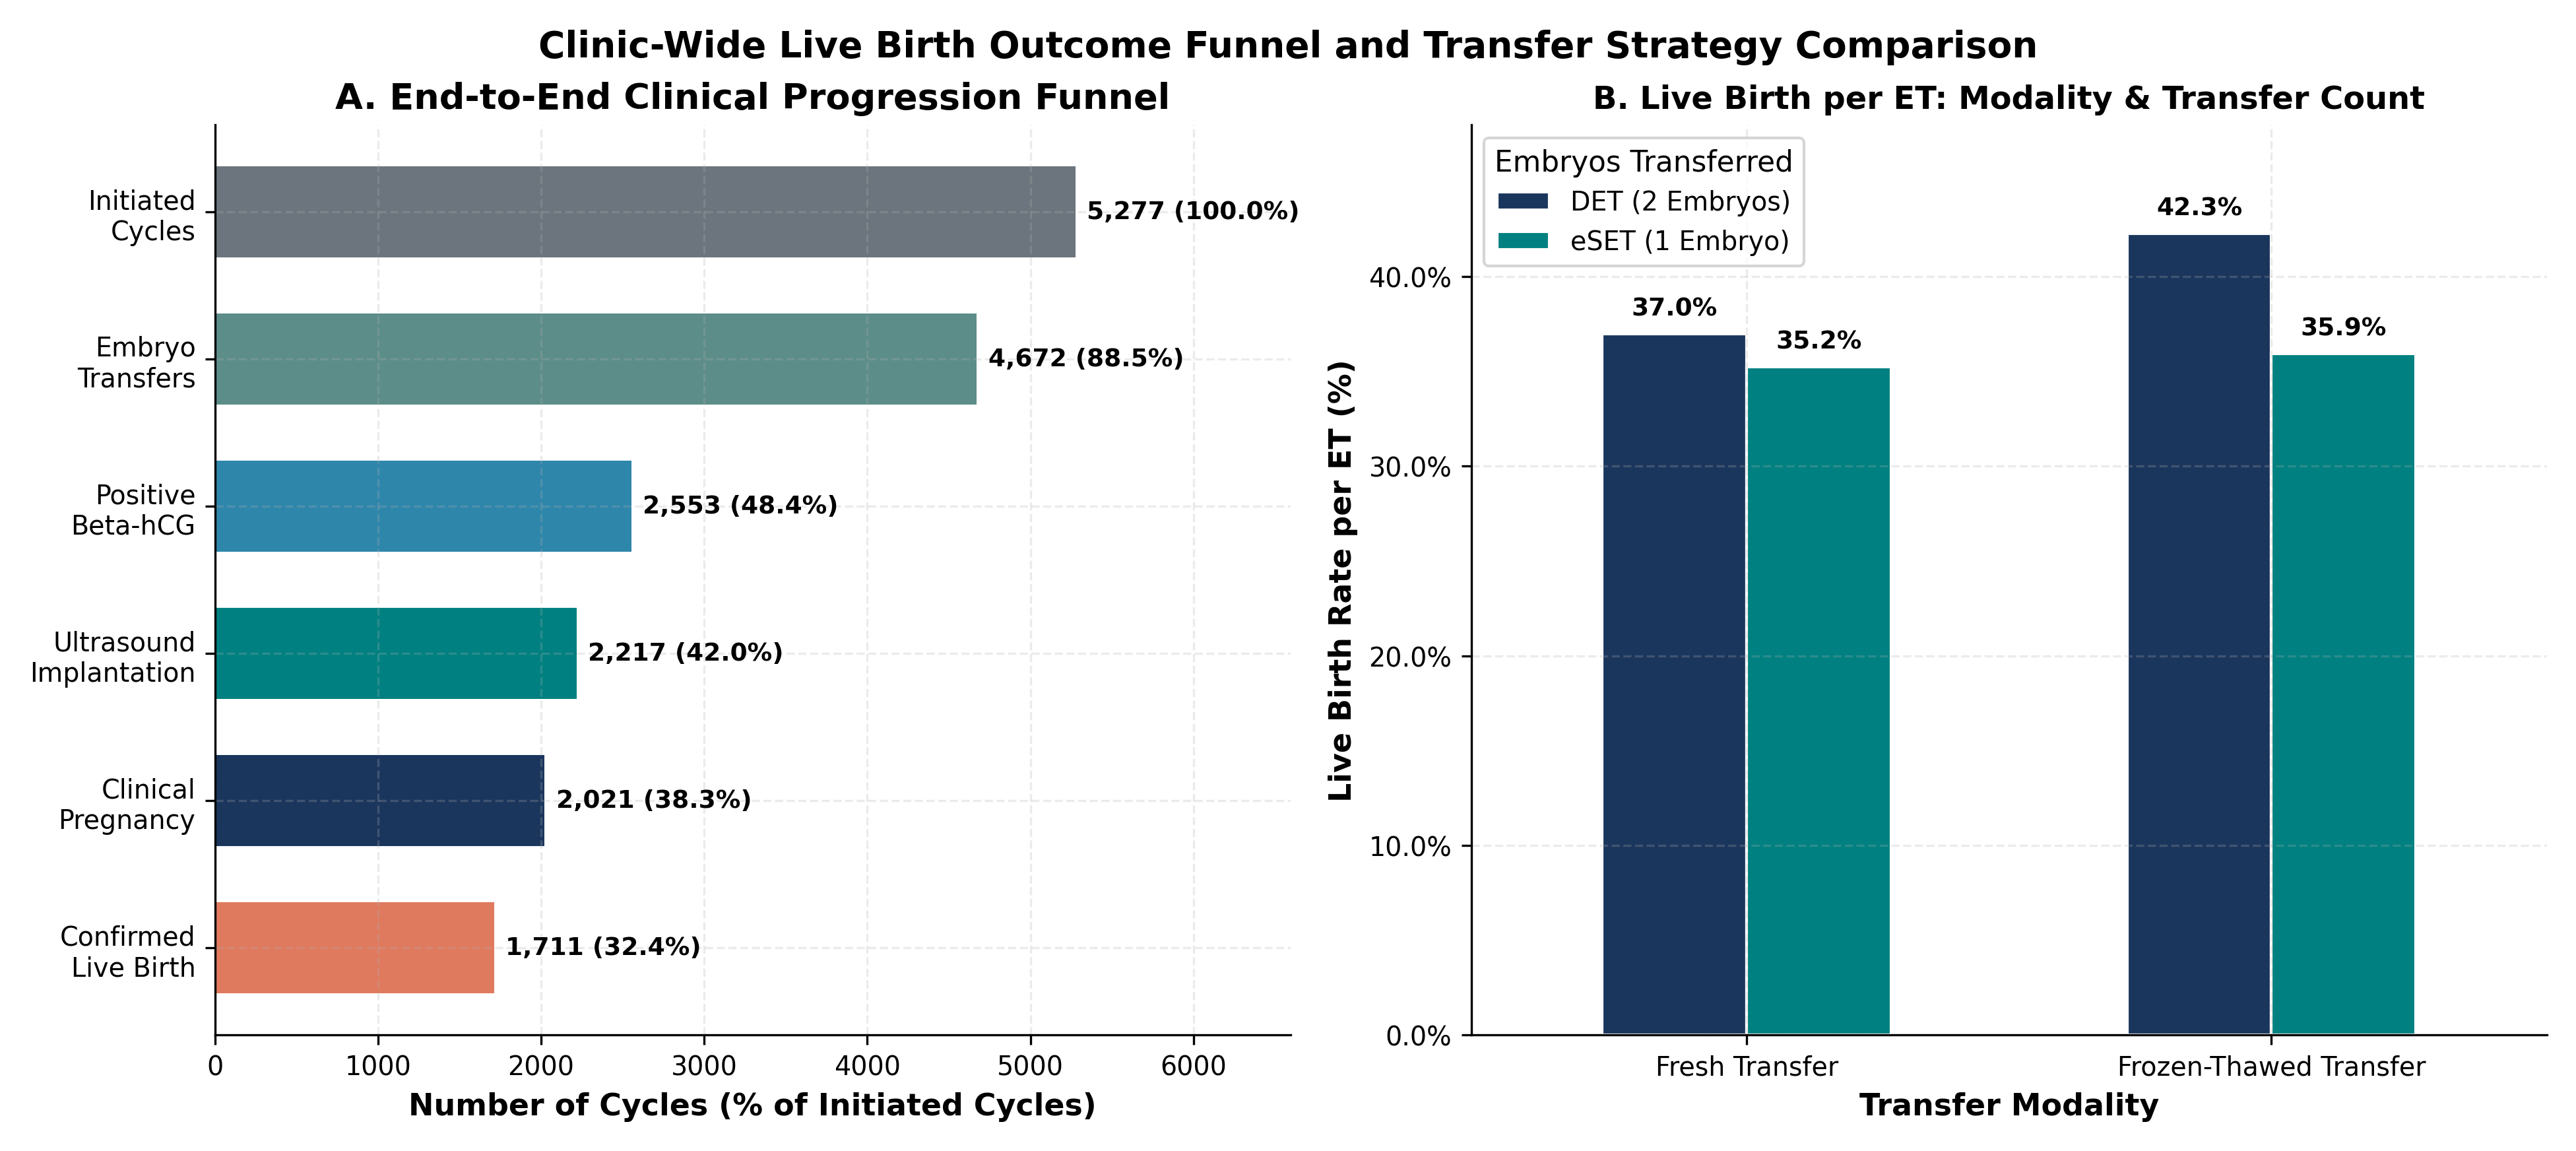

oocytes_retrieved_vs_mature.png


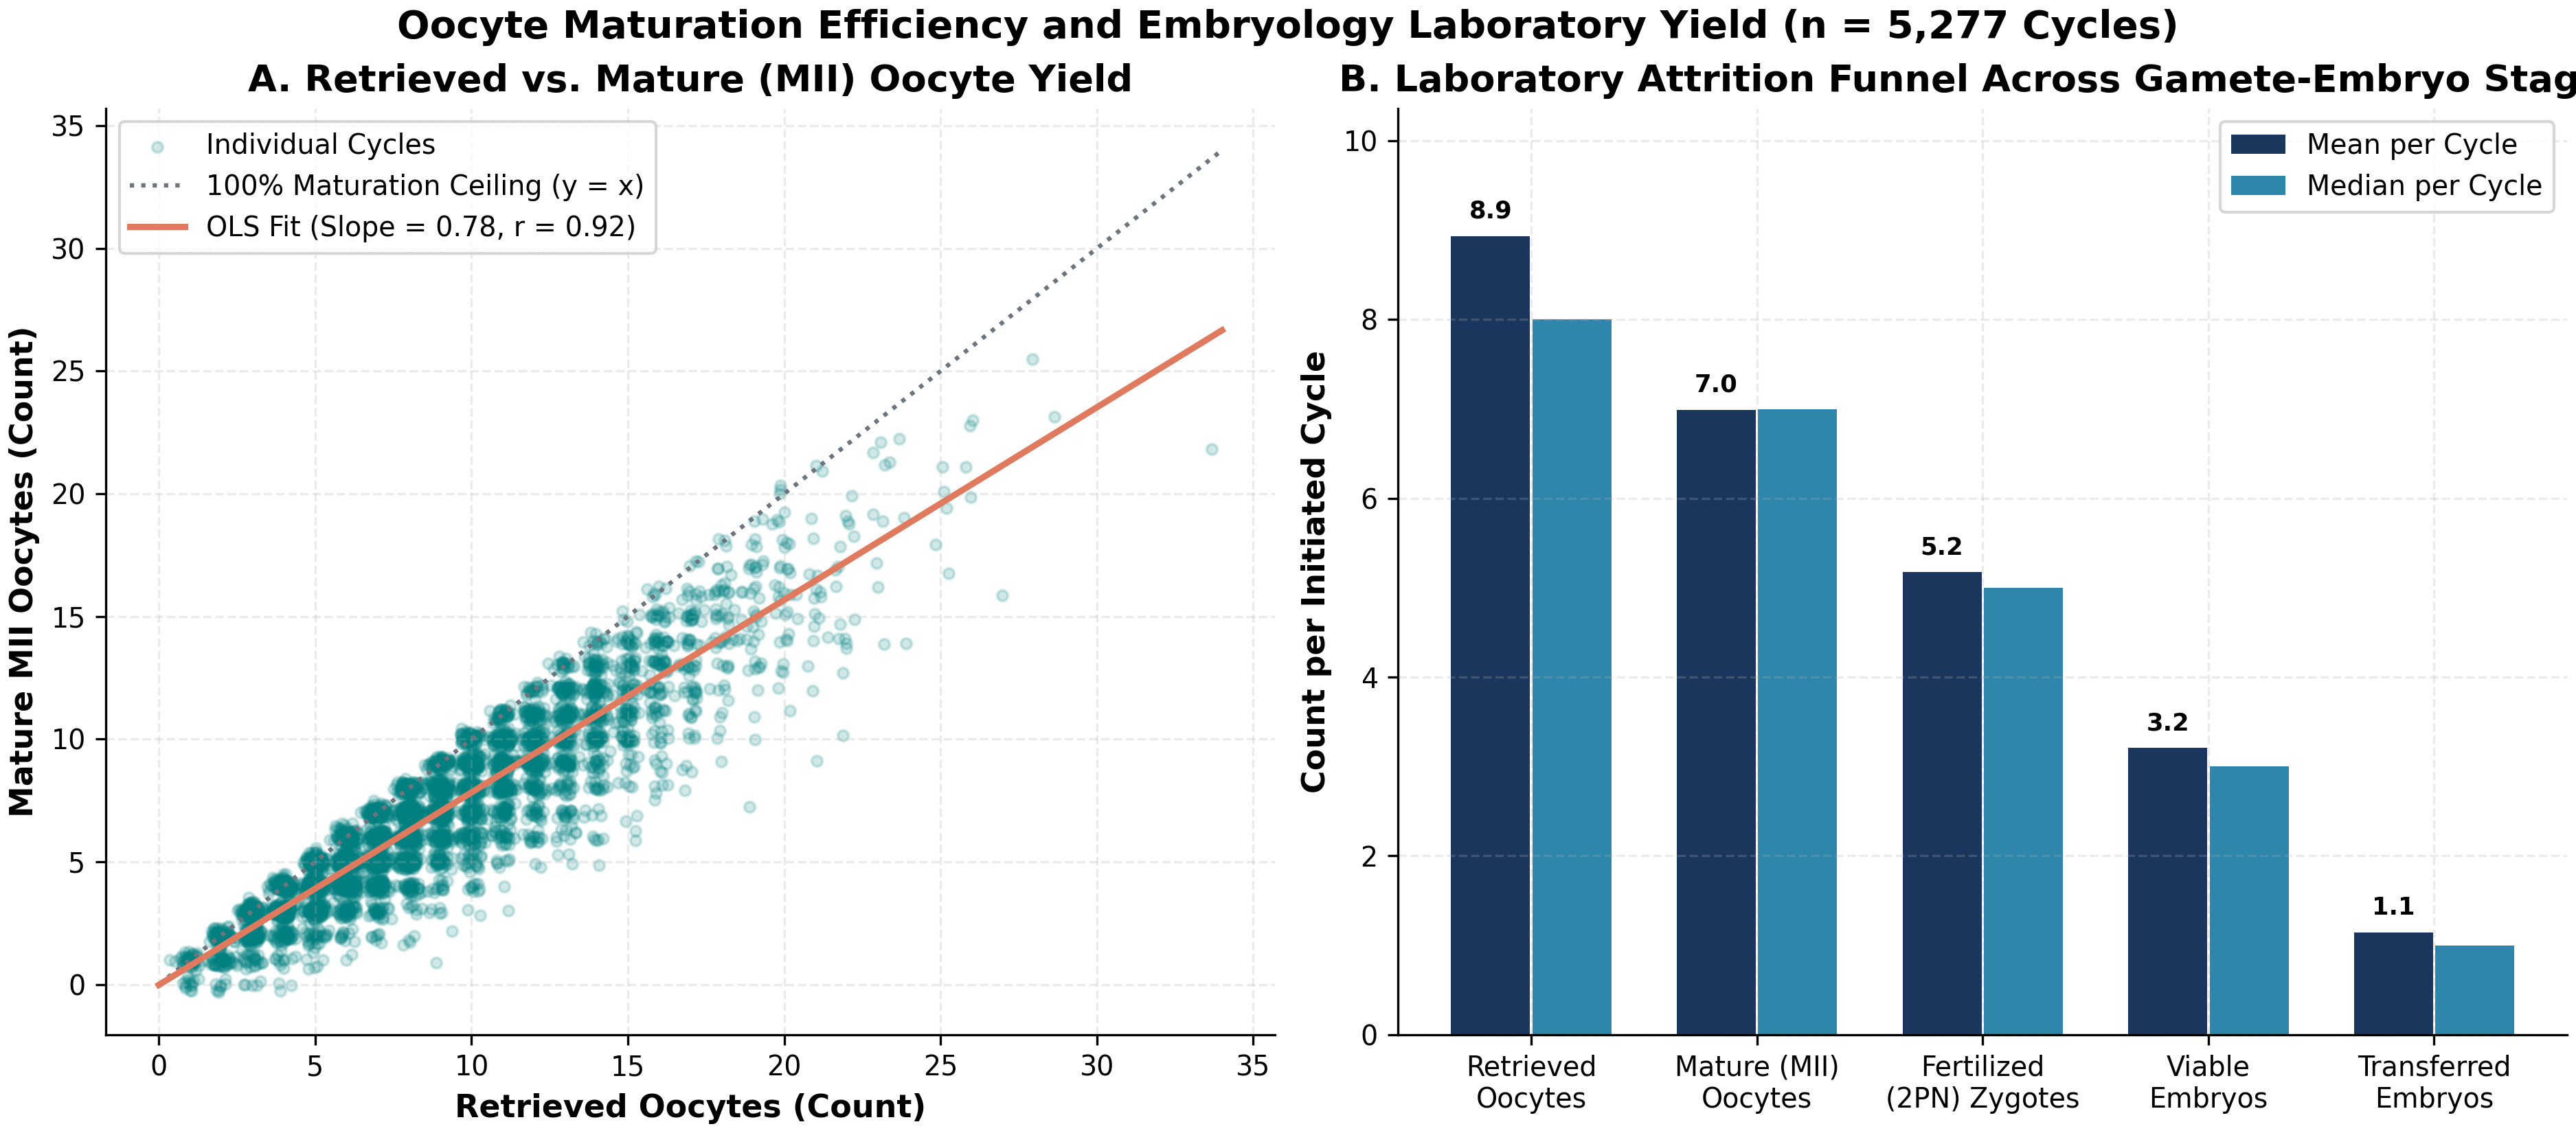

operational_efficiency_cost_effectiveness.png


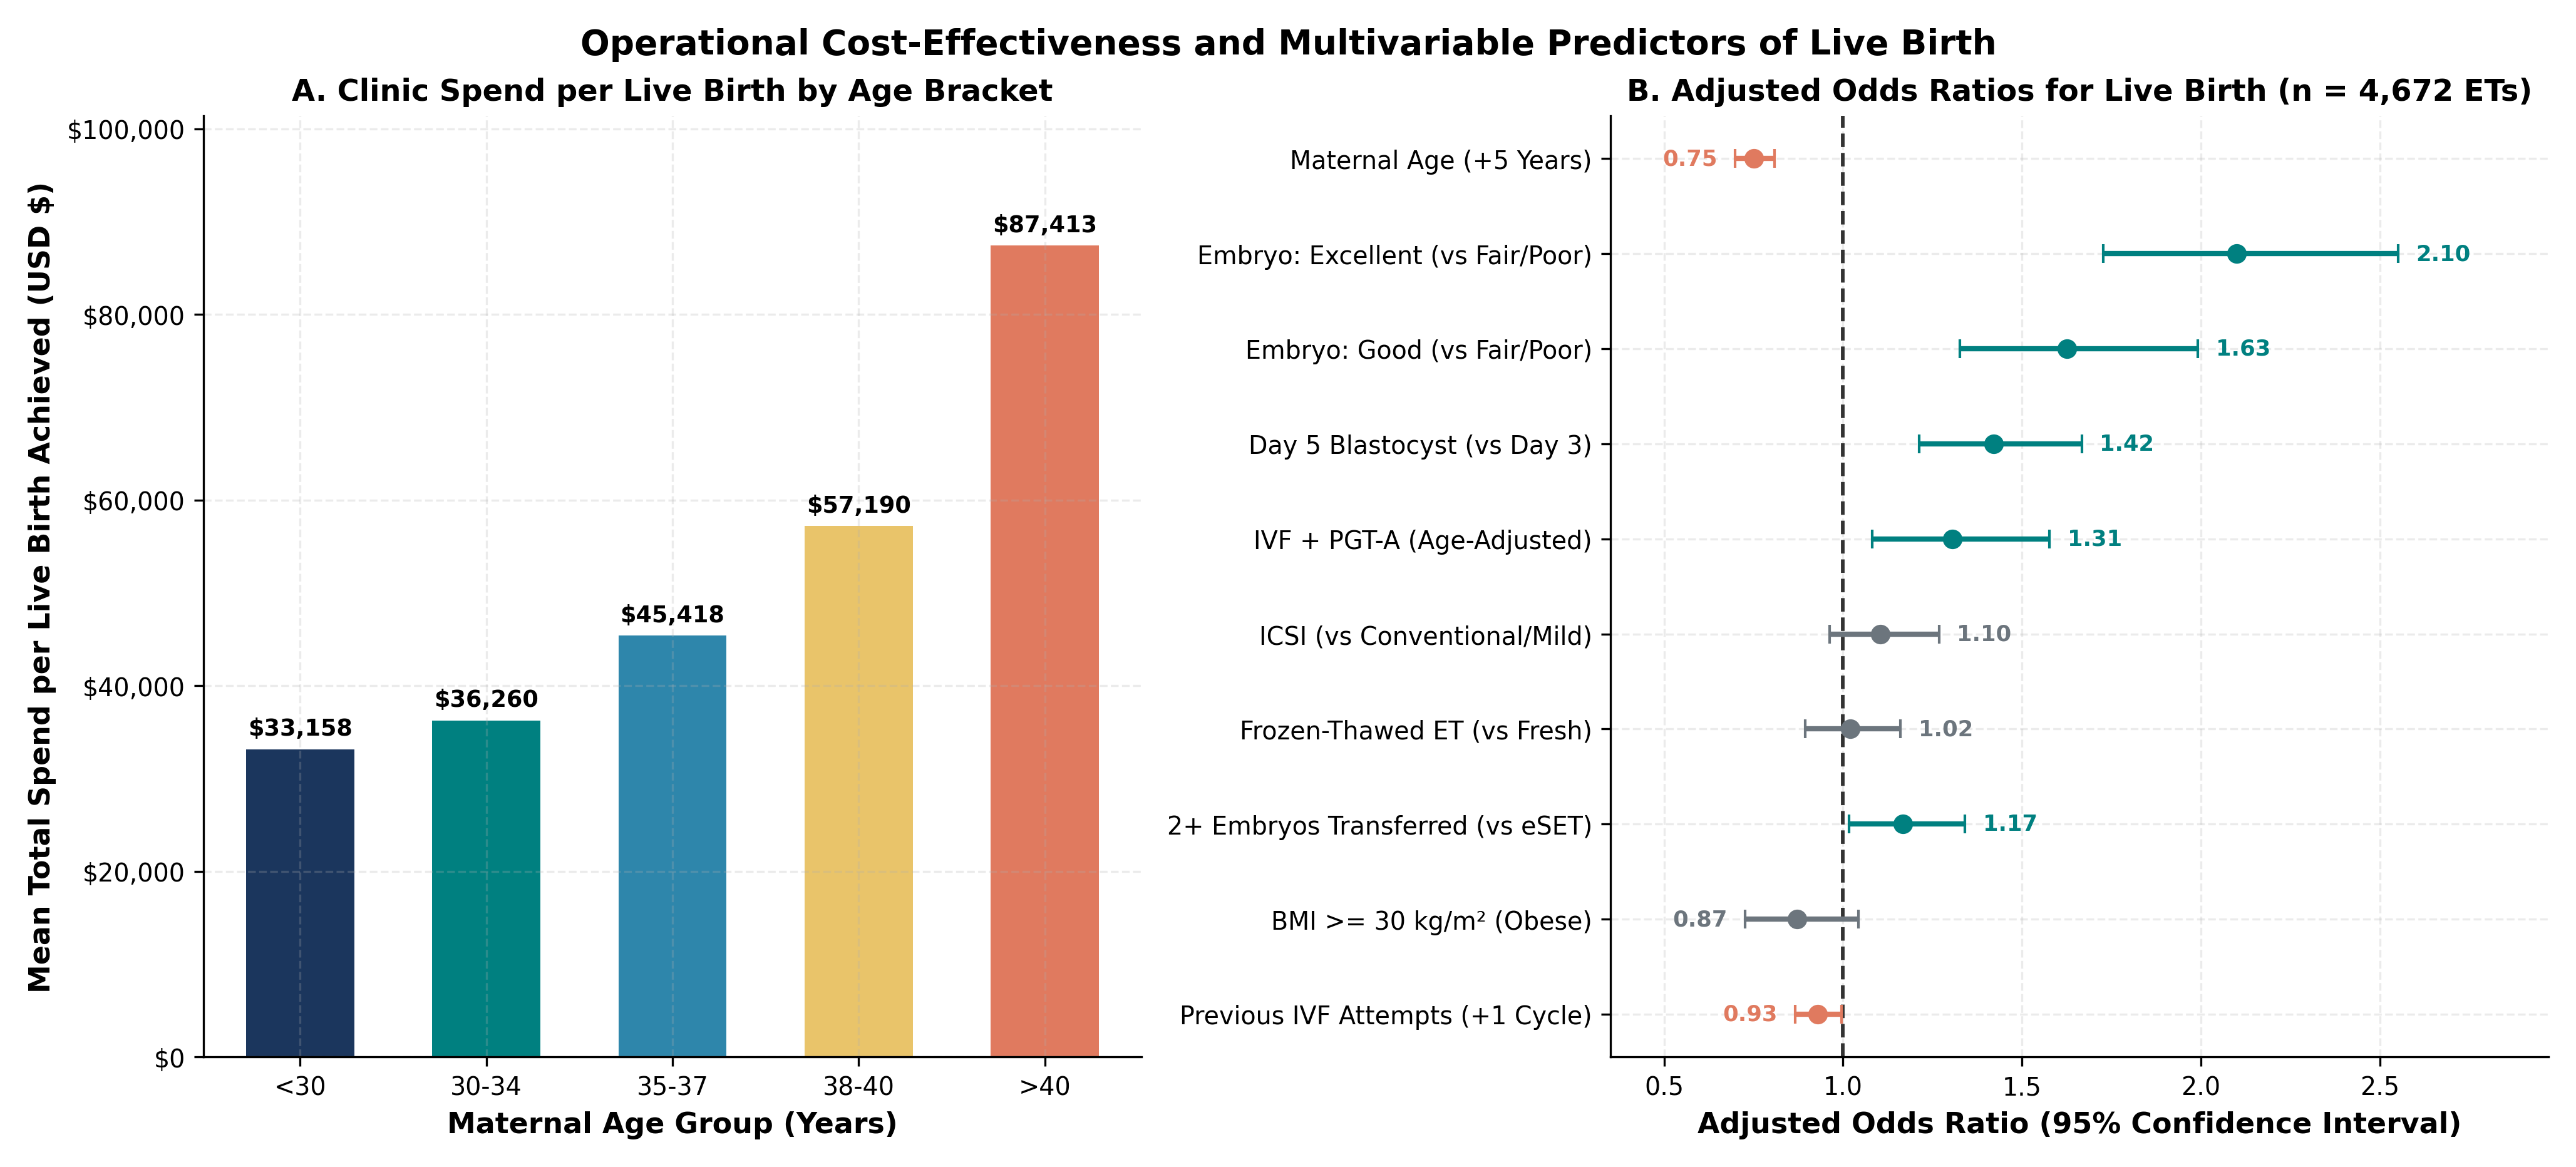

outlier_detection_boxplots.png


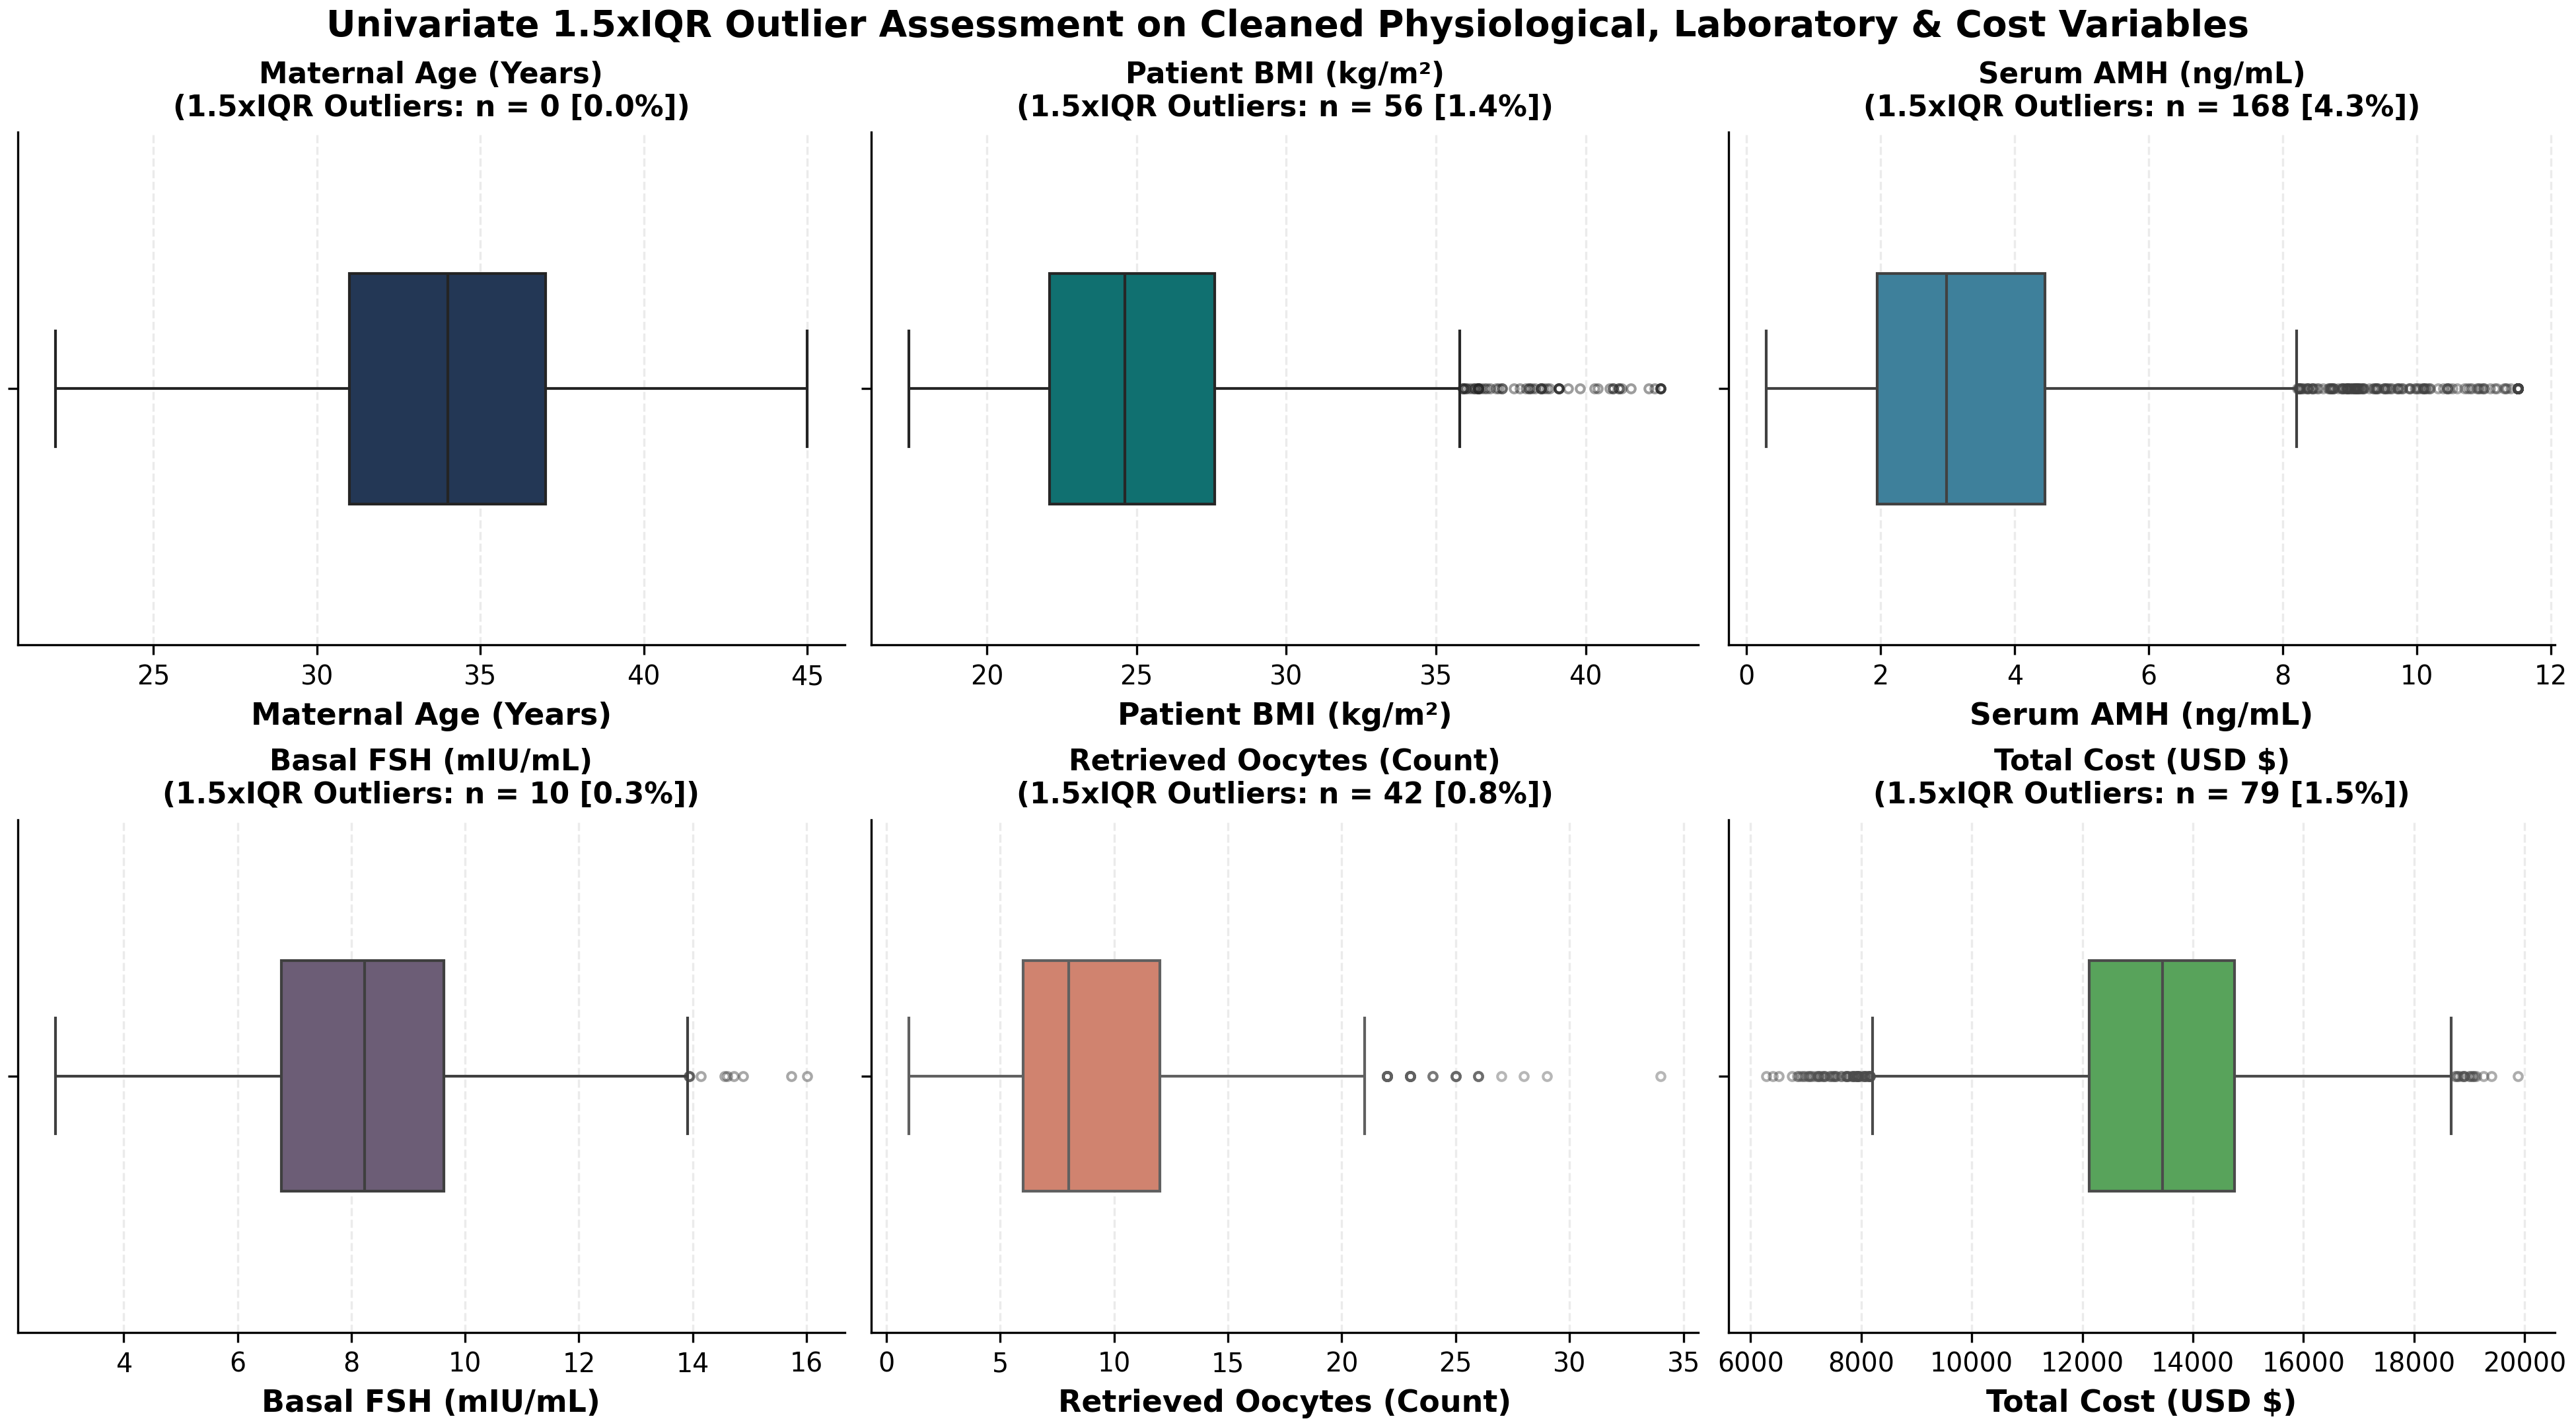

previous_ivf_attempts.png


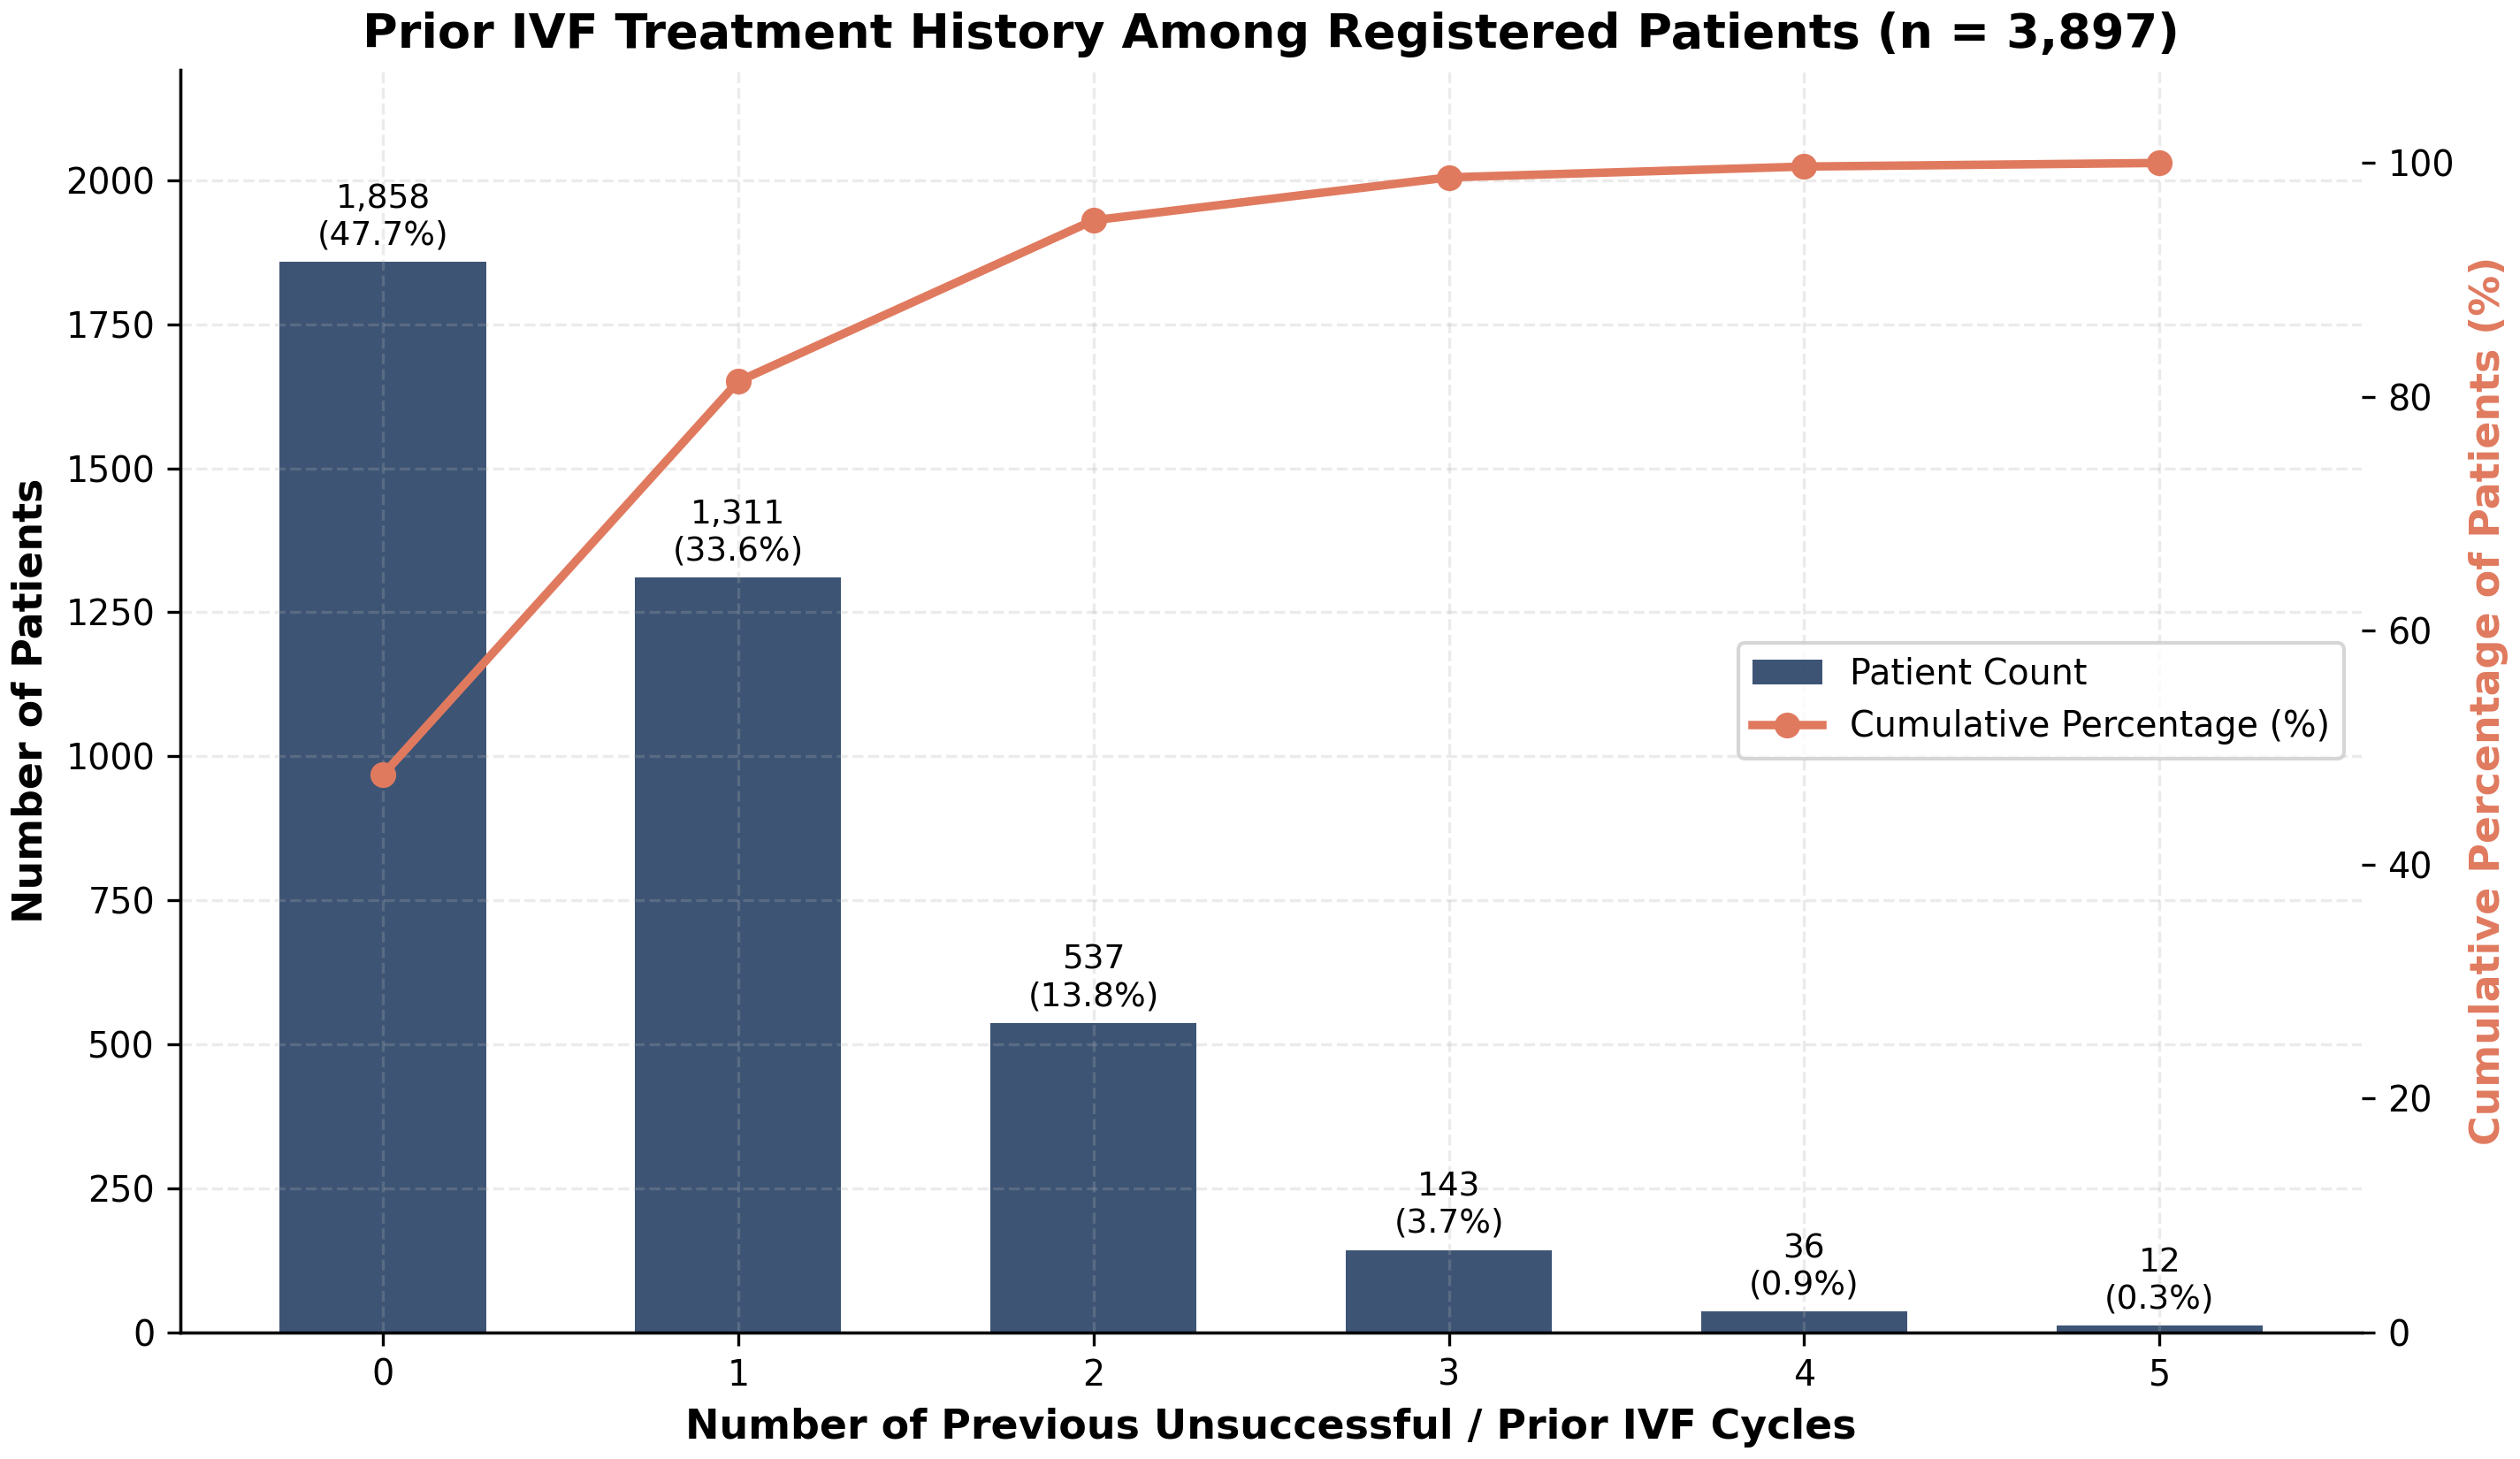

treatment_cost_analysis.png


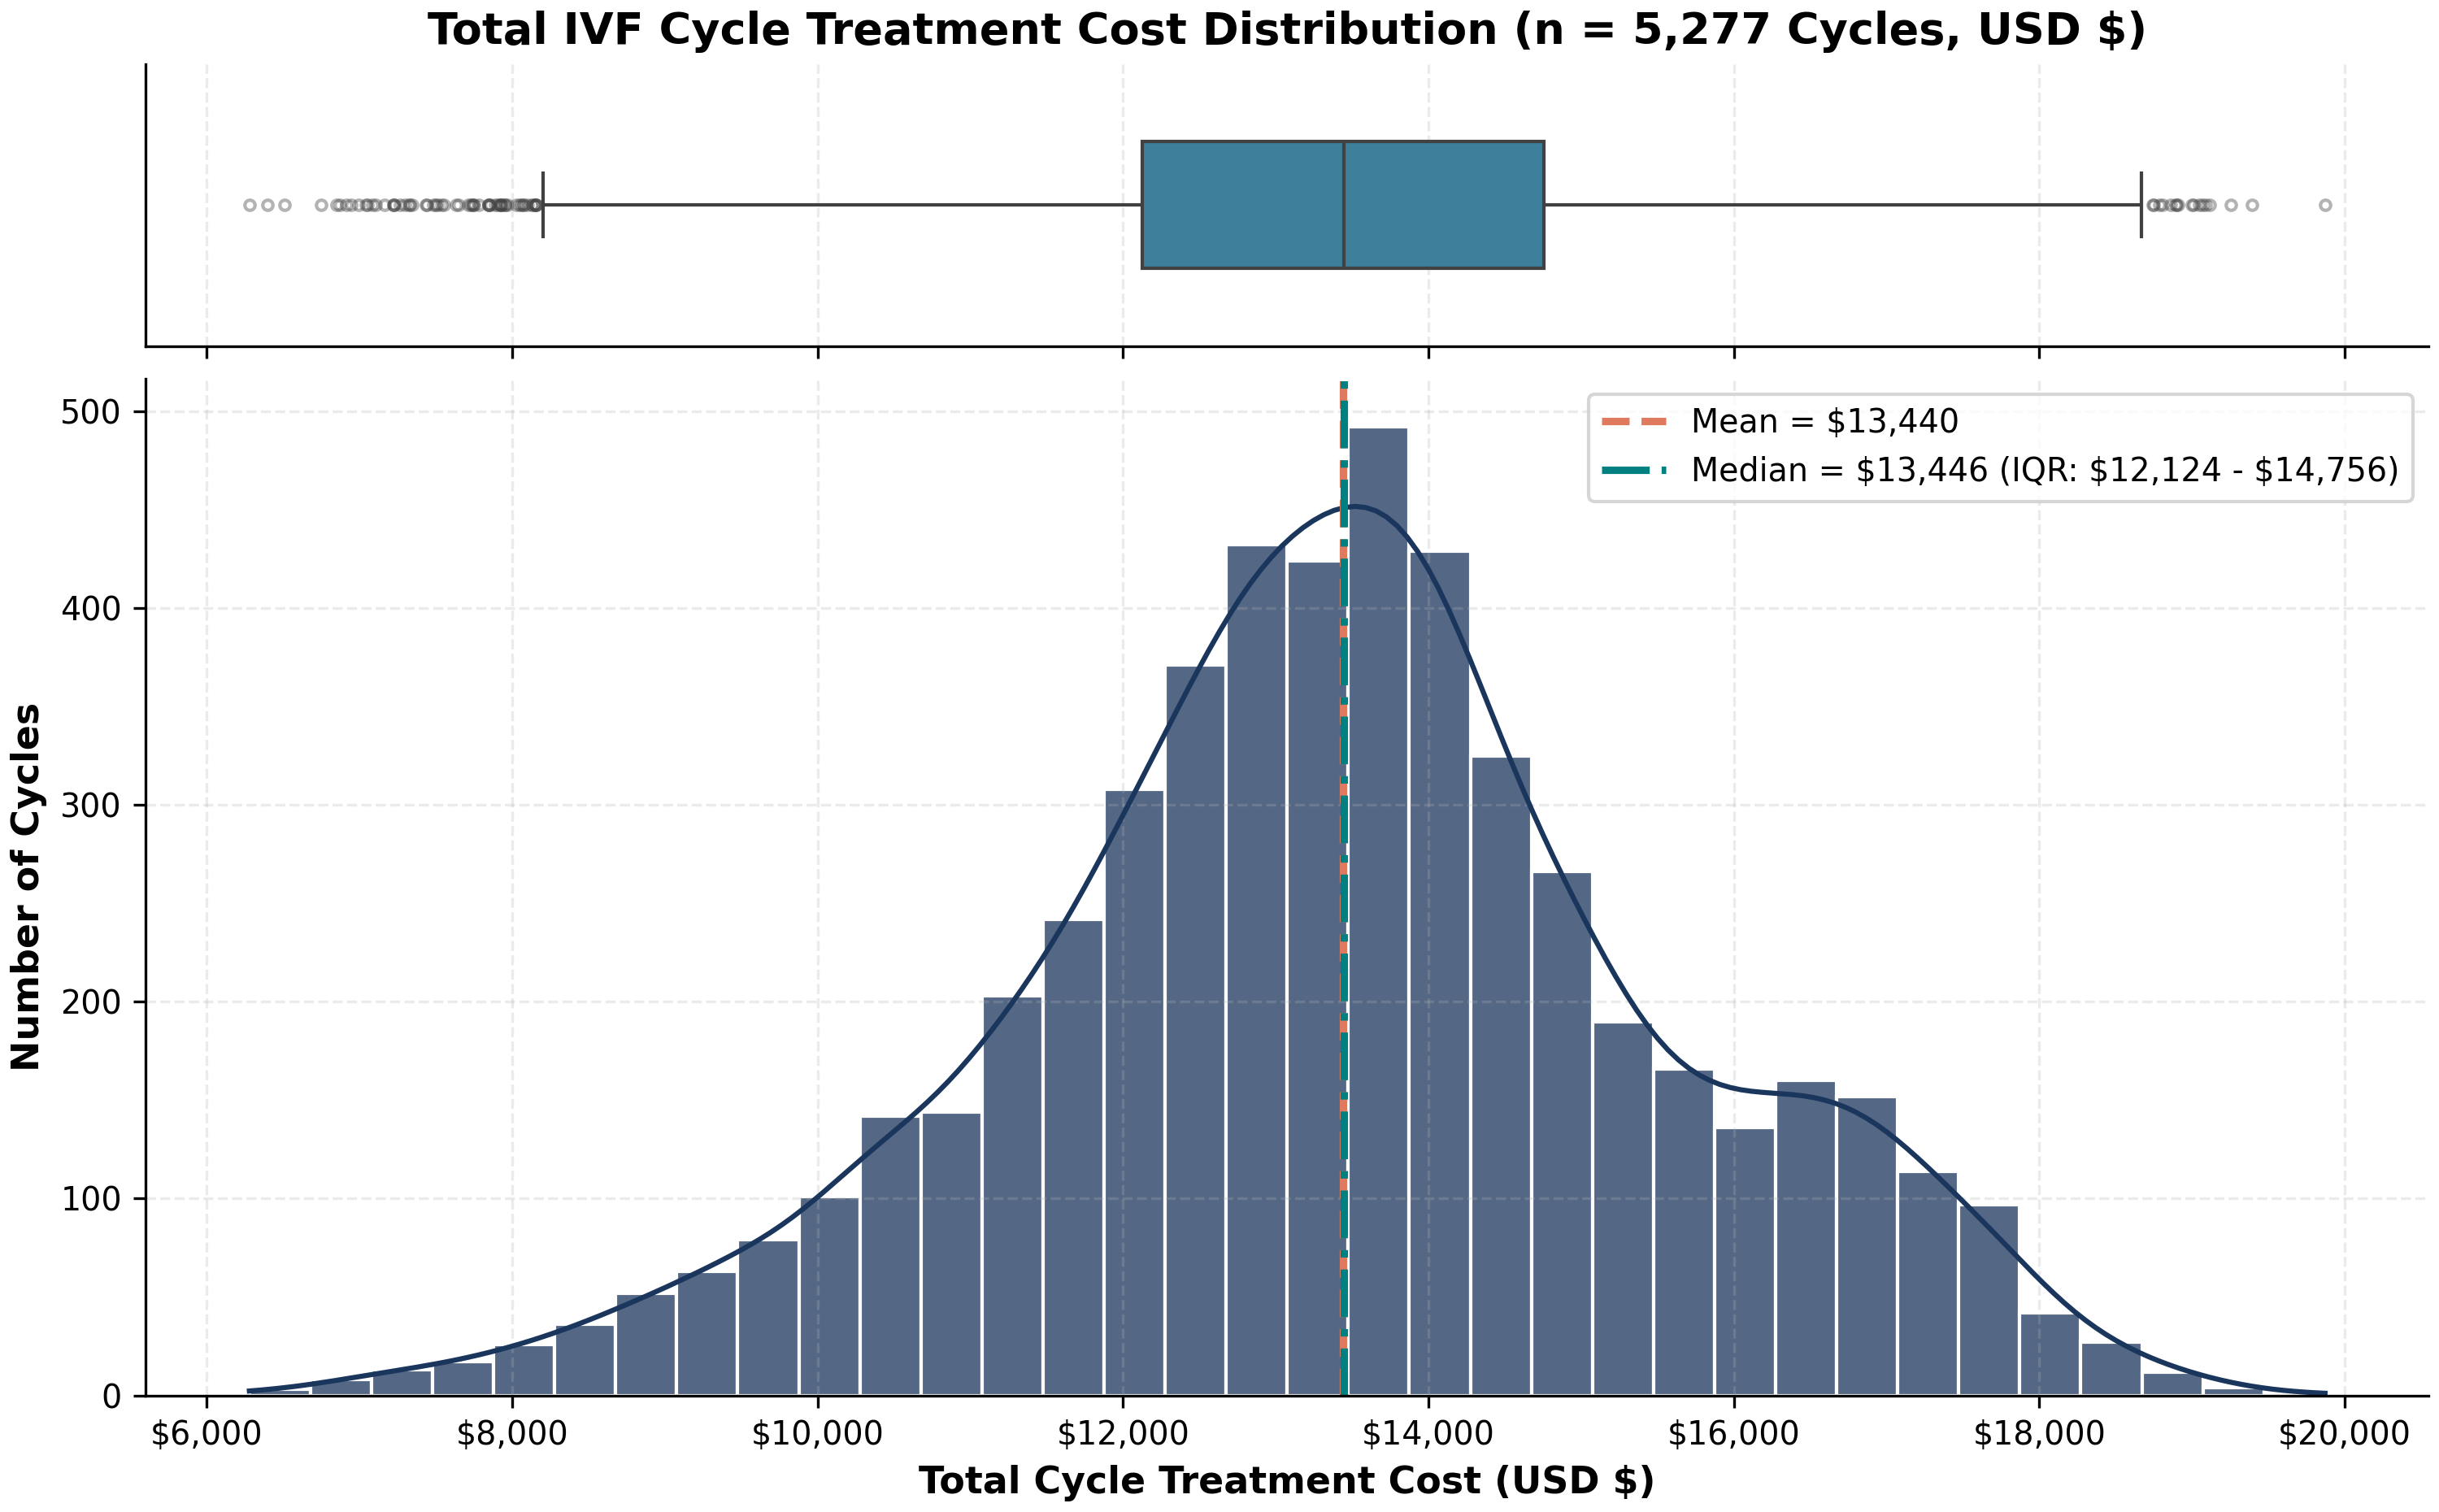

treatment_cost_category_comparison.png


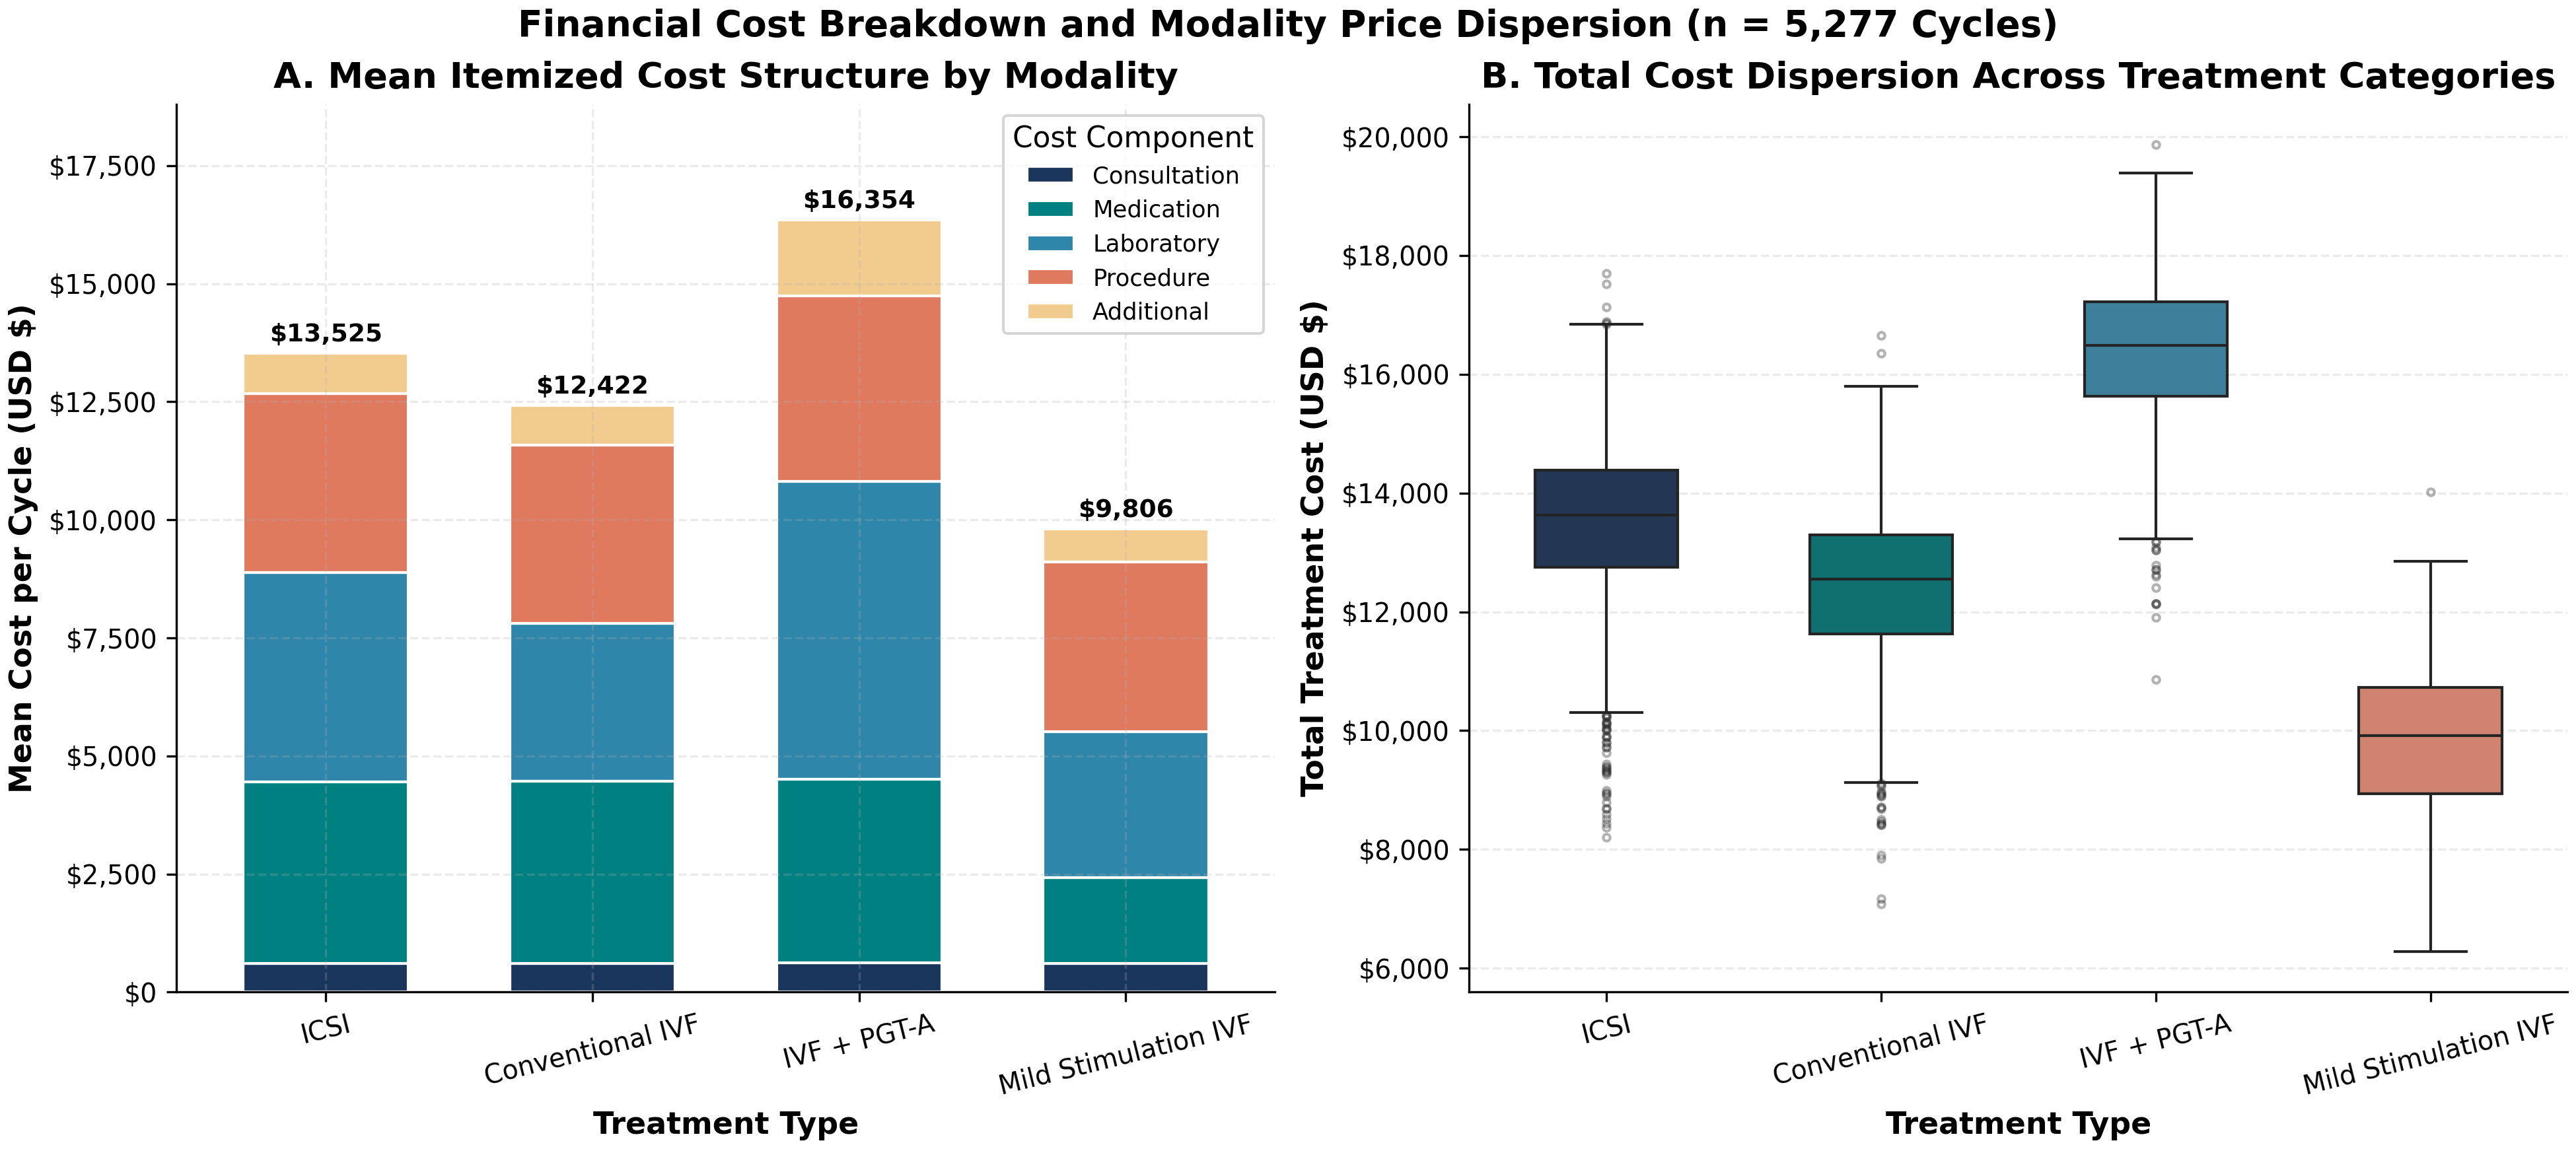

treatment_type_distribution.png


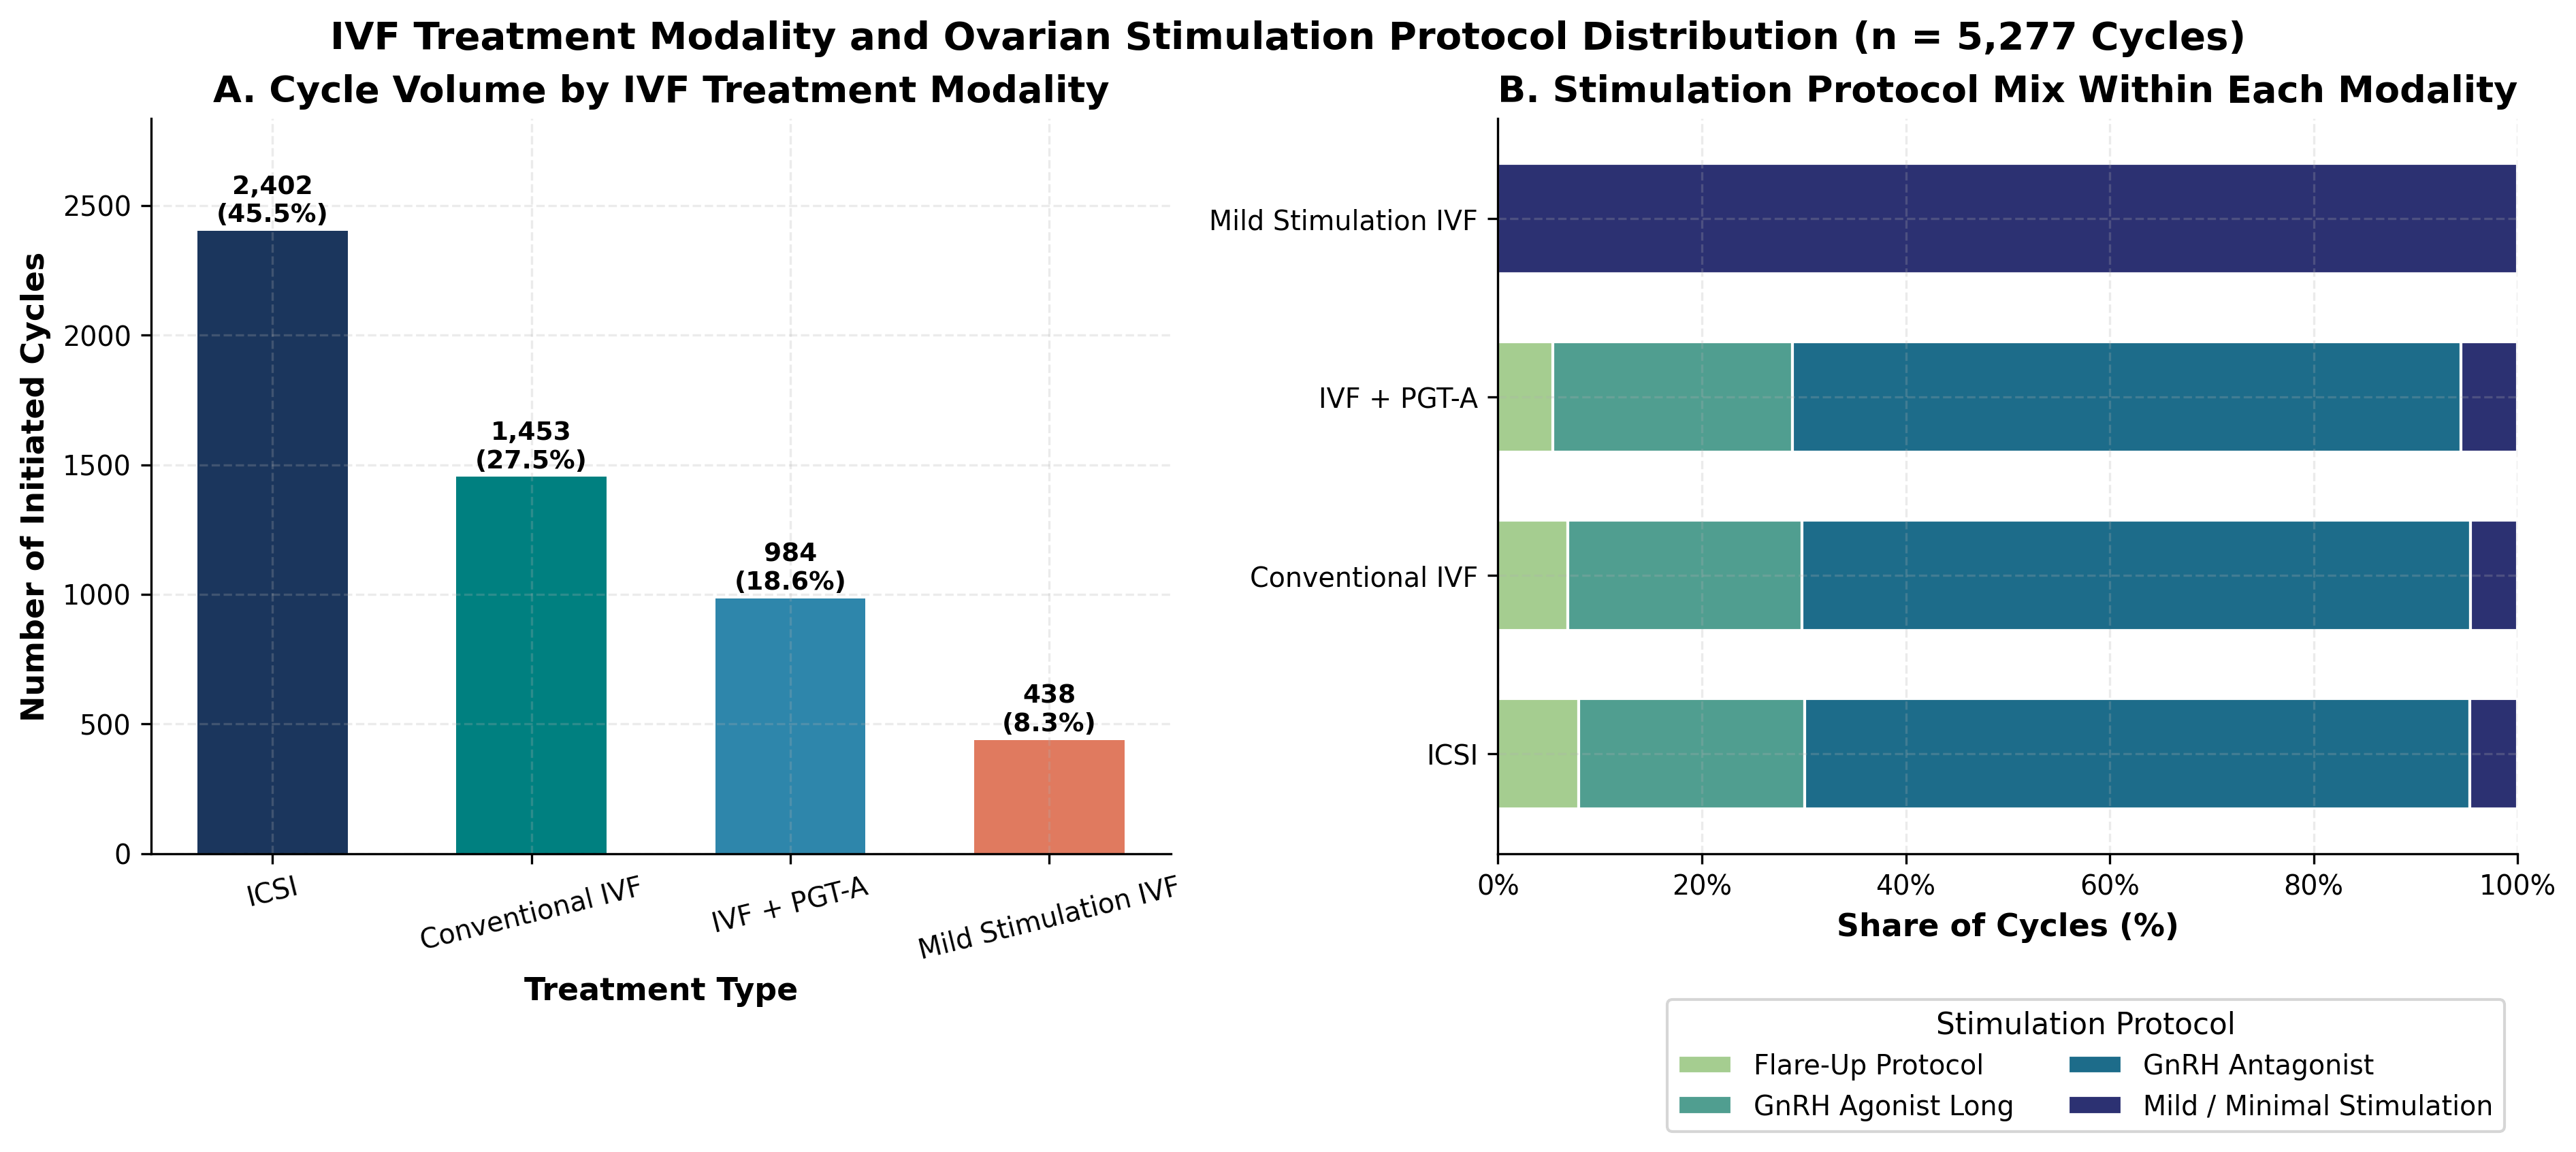

treatment_type_vs_outcome.png


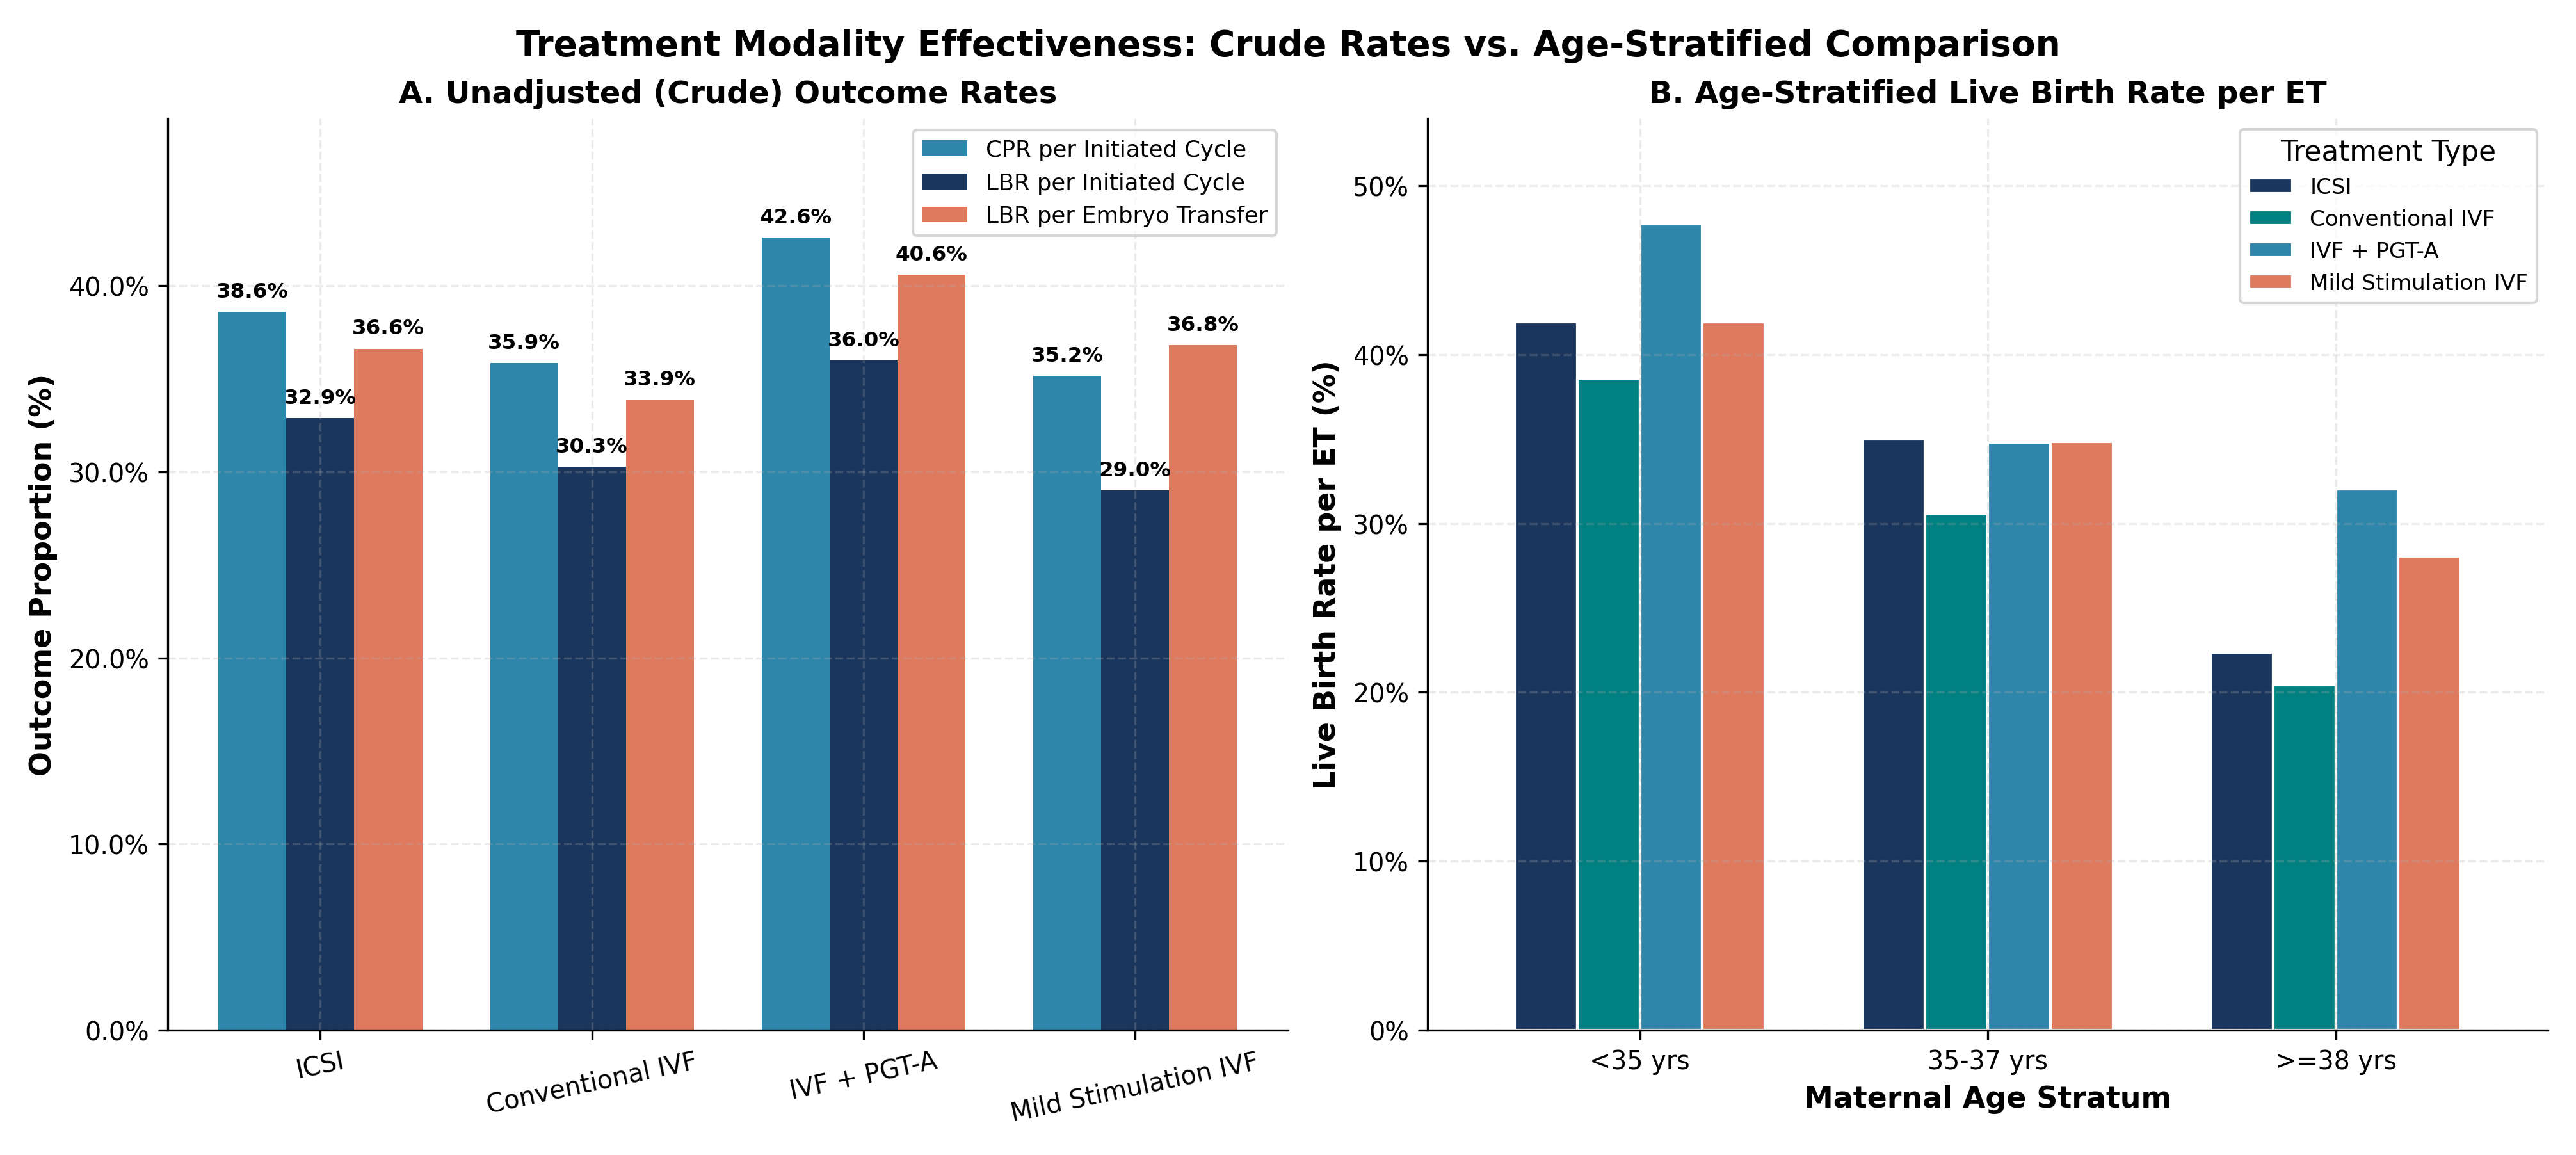

In [11]:
for f in sorted((ROOT/"visualizations").glob("*.png")):
    print(f.name); display(Image(filename=str(f),width=800))

## 16. Key Findings

Outcome percentages below use explicitly stated denominators; estimates describe only these synthetic records.

In [12]:
print("Outcome overview:",results["outcome_rates"]["counts"])
print("Per initiated-cycle rates:",results["outcome_rates"]["per_initiated_cycle_pct"])
print("Per-transfer rates:",results["outcome_rates"]["per_embryo_transfer_pct"])
print("Embryo quality stratification:"); display(pd.DataFrame(results["stratified_outcomes"]["by_embryo_quality_et"]))
print("Age stratification:"); display(pd.DataFrame(results["stratified_outcomes"]["by_age_group"]))

Outcome overview: {'Initiated_Cycles': 5277, 'Embryo_Transfer_Cycles': 4672, 'No_Transfer_Cycles': 605, 'Positive_hCG': 2553, 'Implanted_Cycles': 2217, 'Clinical_Pregnancies': 2021, 'Live_Births': 1711}
Per initiated-cycle rates: {'Transfer_Completion_Rate': 88.54, 'Positive_hCG_Rate': 48.38, 'Cycle_Implantation_Proportion': 42.01, 'Clinical_Pregnancy_Rate': 38.3, 'Live_Birth_Rate': 32.42}
Per-transfer rates: {'Positive_hCG_Rate': 54.64, 'Cycle_Implantation_Proportion': 47.45, 'Clinical_Pregnancy_Rate': 43.26, 'Live_Birth_Rate': 36.62}
Embryo quality stratification:


,Best_Embryo_Quality,Cycles,Transfers,Implantation_per_ET_Pct,CPR_per_ET_Pct,LBR_per_ET_Pct,CPR_per_Cycle_Pct,LBR_per_Cycle_Pct,Mean_Age,Mean_Cost,Median_Cost,Cost_per_Live_Birth
0,Excellent,2324,2324,54.78,49.87,42.04,49.87,42.04,33.07,13896.93,13796.25,33056.77
1,Good,1624,1624,44.27,40.39,34.79,40.39,34.79,34.11,13668.01,13562.76,39286.46
2,Fair,546,546,33.33,30.59,25.46,30.59,25.46,34.76,13220.66,13150.07,51931.51
3,Poor,178,178,24.16,21.91,16.85,21.91,16.85,35.60,13048.60,13061.06,77421.71


Age stratification:


,Age_Group,Cycles,Transfers,Implantation_per_ET_Pct,CPR_per_ET_Pct,LBR_per_ET_Pct,CPR_per_Cycle_Pct,LBR_per_Cycle_Pct,Mean_Age,Mean_Cost,Median_Cost,Cost_per_Live_Birth
0,<30,901,823,54.92,49.94,44.11,45.62,40.29,27.07,13358.73,13331.66,33157.62
1,30-34,1999,1821,51.67,47.50,40.91,43.27,37.27,32.23,13513.46,13495.73,36259.60
2,35-37,1279,1117,44.14,40.02,33.66,34.95,29.40,35.93,13351.96,13401.91,45417.96
3,38-40,709,595,37.65,34.29,28.07,28.77,23.55,38.79,13470.73,13501.06,57190.09
4,>40,389,316,33.86,29.75,18.99,24.16,15.42,42.44,13482.70,13481.80,87412.81


## 17. Business Recommendations

Monitor funnel completion, costs and outcomes with stratification and uncertainty; do not infer treatment effects.

- Maintain stage-specific denominators and follow-up-completion reporting.
- Monitor laboratory funnel conversion, costs, and stratified outcome variation.
- Investigate operational variation in prospectively governed real-world data; the synthetic comparisons are not causal or prescriptive.

## 18. Limitations

Synthetic assumptions, repeated patients/cycles, potential residual confounding, follow-up, missingness repair, and no external validation limit inference.

**Disclaimer:** Entirely synthetic data. Findings are demonstrative and cannot guide clinical patient decisions.

## 19. Conclusion

This reproducible workflow illustrates data quality, descriptive analytics and responsible reporting—not clinical evidence.

**Disclaimer:** Entirely synthetic data. Findings are demonstrative and cannot guide clinical patient decisions.